In [ ]:
import h5py
import os

import pandas as pd
import numpy as np
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.cm import get_cmap


from scipy.signal import find_peaks

mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['axes.titleweight'] = 'bold'
mpl.rcParams['axes.edgecolor'] = 'black'
mpl.rcParams['axes.linewidth'] = 2.0


def plot_h5(h5_file_path, target_spectra=None, output_file_path=None, title = None):
    """
    Plots absorbance spectra from an HDF5 file. If multiple target spectra are provided,
    they are overlaid on a single plot.

    Parameters:
        h5_file_path (str): Path to the HDF5 file.
        target_spectra (str or list of str, optional): Spectra identifiers to match. 
            If None, plots all datasets.
        output_file_path (str, optional): If given, saves the plot to this folder; otherwise, displays it.
        title (str, optional): Title for the plot. If None, a default title is used based on the dataset attributes.

    Returns:
        None
    """
    try:
        if isinstance(target_spectra, str):
            target_spectra = [target_spectra]

        with h5py.File(h5_file_path, 'r') as hdf:
            if target_spectra:
                matching_datasets = [name for name in hdf.keys() if name in target_spectra]
            else:
                matching_datasets = list(hdf.keys())

            if not matching_datasets:
                print(f"No datasets matched the specified criteria.")
                return

            # Create a figure for overlay
            plt.figure(figsize=(12, 7))

            for dataset_name in matching_datasets:
                dataset = hdf[dataset_name]

                data = dataset[:]
                wavelengths = data[:, 0]
                absorbances = data[:, 1]

                ligand = dataset.attrs.get("Ligand", "Unknown")
                ligand_index = dataset.attrs.get("Ligand Index", "Unknown")
                metal = dataset.attrs.get("Metal", "Unknown")
                solvent = dataset.attrs.get("Solvent", "Unknown")
                base = dataset.attrs.get("Base", "No")

                label = f"{dataset_name}"
                plt.plot(wavelengths, absorbances, linewidth = 3.0, label=label)

            # Plot styling
            plt.title(title, fontsize = 24)
            plt.xlabel("Wavelength (nm)", fontsize = 18)
            plt.ylabel("Absorbance", fontsize = 18)
            #plt.legend(fontsize=14)
            plt.grid(False)
            plt.xlim(200, 550)
            plt.ylim(-0.2, 2.5)

            if output_file_path:
                os.makedirs(output_file_path, exist_ok=True)
                output_file = os.path.join(output_file_path, "overlaid_spectra.png")
                plt.savefig(output_file, bbox_inches='tight')
                print(f"Overlaid plot saved: {output_file}")
            else:
                plt.show()

            plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")

def plot_h5_blue_scheme(h5_file_path, target_spectra=None, output_file_path=None, title=None):
    """
    Plots absorbance spectra from an HDF5 file using a blue color scheme.

    Parameters:
        h5_file_path (str): Path to the HDF5 file.
        target_spectra (str or list of str, optional): Spectra identifiers to match. 
            If None, plots all datasets.
        output_file_path (str, optional): If given, saves the plot to this folder; otherwise, displays it.
        title (str, optional): Title for the plot. If None, a default title is used based on the dataset attributes.

    Returns:
        None
    """
    try:
        if isinstance(target_spectra, str):
            target_spectra = [target_spectra]

        with h5py.File(h5_file_path, 'r') as hdf:
            if target_spectra:
                matching_datasets = [name for name in hdf.keys() if name in target_spectra]
            else:
                matching_datasets = list(hdf.keys())

            if not matching_datasets:
                print(f"No datasets matched the specified criteria.")
                return

            # Set up the color palette using Blues
            cmap = get_cmap("Blues")
            num_colors = len(matching_datasets)
            colors = [cmap(i / max(num_colors, 1)) for i in range(1, num_colors + 1)]

            # Create a figure for overlay
            plt.figure(figsize=(12, 7),dpi=600)

            for idx, dataset_name in enumerate(matching_datasets):
                dataset = hdf[dataset_name]
                data = dataset[:]
                wavelengths = data[:, 0]
                absorbances = data[:, 1]

                label = f"{dataset_name}"
                plt.plot(
                    wavelengths,
                    absorbances,
                    linewidth=3.0,
                    label=label,
                    color=colors[idx]
                )

            # Plot styling
            plt.title(title, fontsize=24)
            plt.xlabel("Wavelength (nm)", fontsize=18)
            plt.ylabel("Absorbance", fontsize=18)
            plt.legend(fontsize=16)
            plt.grid(False)
            plt.xlim(200, 550)
            plt.ylim(-0.2, 2.5)

            if output_file_path:
                os.makedirs(output_file_path, exist_ok=True)
                output_file = os.path.join(output_file_path, "overlaid_spectra_blue.svg")
                plt.savefig(output_file, bbox_inches='tight')
                print(f"Blue scheme plot saved: {output_file}")
            else:
                plt.show()

            plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")
      
def plot_h5_controls(input_h5, controls_h5, target_spectra=None, output_file_path=None, title=None):
    """
    Plots the absorbance spectra for a target dataset (or all datasets if no target specified) and overlays spectra 
    from both ligand and metal control datasets with matching solvent, using a colorblind-friendly palette.

    Parameters:
        input_h5 (str): Path to the input HDF5 file containing the target spectra.
        controls_h5 (str): Path to the HDF5 file containing control spectra.
        target_spectra (str, optional): The name of the target spectra to plot (e.g., "A13_16_run_2_A01"). 
                                        If None, all datasets in the input file are plotted.
        output_file_path (str, optional): Folder path to save the plots. If None, plots are displayed without saving.
        title (str, optional): Title for the plot. If None, a default title is used based on the dataset attributes.

    Returns:
        None
    """
    linewidth = 3.0
    try:
        palette = sns.color_palette("colorblind")

        with h5py.File(input_h5, 'r') as input_hdf, h5py.File(controls_h5, 'r') as control_hdf:
            # Identify the datasets to plot
            datasets_to_plot = (
                [target_spectra] if target_spectra else list(input_hdf.keys())
            )

            if not datasets_to_plot:
                print("No datasets found to plot.")
                return

            for target_dataset_name in datasets_to_plot:
                # Check if the target dataset exists
                if target_dataset_name not in input_hdf:
                    print(f"Dataset '{target_dataset_name}' not found in input file.")
                    continue

                target_dataset = input_hdf[target_dataset_name]

                # Retrieve target dataset data and metadata               
                target_data = target_dataset[:]
                wavelengths = target_data[:, 0]  # First column is Wavelength
                target_absorbances = target_data[:, 1]  # Second column is Absorbance
                metal = target_dataset.attrs.get("Metal", "Unknown")
                ligand_index = target_dataset.attrs.get("Ligand Index", "Unknown")
                ligand = target_dataset.attrs.get("Ligand", "Unknown")
                solvent = target_dataset.attrs.get("Solvent", "Unknown")
                base = target_dataset.attrs.get("Base", "No")
                sample_type = target_dataset.attrs.get("Sample Type","Unknown")

                # Create a new plot
                plt.figure(figsize=(10, 6))
                target_color = palette[0]  # First color for the target spectrum
                control_colors = iter(palette[1:])  # Remaining colors for control spectra

                # Plot the target spectrum
                plt.plot(
                    wavelengths,
                    target_absorbances,
                    label="Sample Mixture",
                    linewidth=linewidth,
                    color=target_color,
                )

                # Search for matching control datasets (ligand and metal controls)
                ligand_control_plotted = False
                metal_control_plotted = False

                for control_dataset_name in control_hdf.keys():
                    control_dataset = control_hdf[control_dataset_name]
                    control_ligand = control_dataset.attrs.get("Ligand", "Unknown")
                    control_metal = control_dataset.attrs.get("Metal", "Unknown")
                    control_solvent = control_dataset.attrs.get("Solvent", "Unknown")
                    control_base = control_dataset.attrs.get("Base", "Unknown")

                    control_data = control_dataset[:]
                    control_wavelengths = control_data[:, 0]  # First column is Wavelength
                    control_absorbances = control_data[:, 1]  # Second column is Absorbance

                    # Match ligand and solvent for ligand control
                    if control_ligand == ligand and control_solvent == solvent:
                        plt.plot(
                            control_wavelengths,
                            control_absorbances,
                            linewidth = linewidth,
                            label=f"Ligand {ligand_index} in {solvent}",
                            color=next(control_colors, "gray"),  # Fallback to gray if colors run out
                        )
                        ligand_control_plotted = True

                    # Match metal and solvent for metal control
                    if control_metal == metal and control_solvent == solvent and control_base == base:
                        
                        formatted_metal_names = {
                            "Ni(NO3)2 6H2O": r"Ni(NO$_3$)$_2$ • 6H$_2$O",
                            "NiBr2 Diglyme": r"NiBr$_2$ • diglyme",
                            "Ni(acac)2":     r"Ni(acac)$_2$",
                        }
                        metal = formatted_metal_names.get(metal, metal)

                        formatted_base_names = {
                            "No": r"No",
                            "K2CO3": r"K$_2$CO$_3$",
                            "DIPEA": r"DIPEA"
                        }
                        base = formatted_base_names.get(base, base)
                        
                        plt.plot(
                            control_wavelengths,
                            control_absorbances,
                            linewidth = linewidth,
                            label=f"{metal} in {solvent}",
                            color=next(control_colors, "black"),  # Use black or next color
                        )
                        metal_control_plotted = True

                # Add title and labels
                if sample_type == "Sample":
                    if title == None:
                        if base == "No":
                            plt.title(f"{ligand} ({ligand_index})" "\n"
                                      f"and {metal} in {solvent}", fontsize = 24)
                        else:
                            plt.title(f"{ligand} ({ligand_index})" "\n" 
                                      f"and {metal} in {solvent} with {base}", fontsize = 24)
                    else:
                        plt.title(title, fontsize = 24)
    
                    plt.xlabel("Wavelength (nm)", fontsize = 18)
                    plt.ylabel("Absorbance", fontsize = 18)
                    plt.legend(fontsize = 14)
                    plt.grid(False)
                    plt.xlim(200, 550)
                    plt.ylim(-0.5, 2.4)
                    plt.tick_params(axis='both', width=2, labelsize=14)

                else:
                    if title == None:
                        if base == "No":
                            plt.title(f"{ligand} ({ligand_index})" "\n"
                                      f"and {metal} in {solvent}", fontsize = 24)
                        else:
                            plt.title(f"{ligand} ({ligand_index})" "\n" 
                                      f"and {metal} in {solvent} with {base}", fontsize = 24)
                    else:
                        plt.title(title, fontsize = 24)
    
                    plt.xlabel("Wavelength (nm)", fontsize = 18)
                    plt.ylabel("Absorbance", fontsize = 18)
                    plt.legend(fontsize = 14)
                    plt.grid(False)
                    plt.xlim(200, 550)
                    plt.ylim(-0.5, 2.4)
                    plt.tick_params(axis='both', width=2, labelsize=14)


                # Save or display the plot
                if output_file_path:
                    output_file = os.path.join(output_file_path, f"{target_dataset_name}.png")
                    plt.savefig(output_file, bbox_inches="tight")
                    print(f"Plot saved: {output_file}")
                else:
                    plt.show()

                plt.close()

                if not ligand_control_plotted:
                    print(f"No matching ligand control datasets found for ligand '{ligand}' and solvent '{solvent}'.")

                if not metal_control_plotted:
                    print(f"No matching metal control datasets found for metal '{metal}' and solvent '{solvent}'.")

    except Exception as e:
        print(f"An error occurred: {e}")

In [21]:
H5_COLORS = [
    "#08306B",  # 1  navy
    "#6A51A3",  # 2  purple
    "#238B45",  # 3  green
    "#4292C6",  # 4  sky blue
    "#9E7BC8",  # 5  light purple
    "#74C476",  # 6  light green
    "#3F007D",  # 7  deep indigo
    "#00441B",  # 8  dark green
    "#9ECAE1",  # 9  pale blue
    "#BCBDDC",  # 10 lavender
]


def plot_h5_colors(h5_file_path, target_spectra=None, output_file_path=None,
                   title=None, colors=None):
    """
    Plots absorbance spectra from an HDF5 file using hardcoded colors (max 10 datasets).

    Parameters:
        h5_file_path (str): Path to the HDF5 file.
        target_spectra (str or list of str, optional): Dataset names to plot, in the
            order they should be colored. If None, plots all datasets in the file.
        output_file_path (str, optional): Folder to save the SVG into; otherwise the
            plot is displayed.
        title (str, optional): Plot title.
        colors (list of str, optional): Override H5_COLORS for this call.

    Returns:
        None
    """
    try:
        palette = colors if colors is not None else H5_COLORS

        if isinstance(target_spectra, str):
            target_spectra = [target_spectra]

        with h5py.File(h5_file_path, 'r') as hdf:
            if target_spectra:
                # Keep the user's order so colors map predictably
                matching_datasets = [name for name in target_spectra if name in hdf]
            else:
                matching_datasets = list(hdf.keys())

            if not matching_datasets:
                print("No datasets matched the specified criteria.")
                return

            if len(matching_datasets) > len(palette):
                print(f"Warning: {len(matching_datasets)} datasets found but only "
                      f"{len(palette)} colors defined. Plotting the first {len(palette)}.")
                matching_datasets = matching_datasets[:len(palette)]

            # svg.fonttype='none' keeps text as real text (crisp, editable);
            # use 'path' instead if fonts look wrong after pasting into ChemDraw.
            with plt.rc_context({
                "svg.fonttype": "none",
                "font.family": "sans-serif",
                "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
            }):
                plt.figure(figsize=(12, 7))

                for idx, dataset_name in enumerate(matching_datasets):
                    data = hdf[dataset_name][:]
                    wavelengths = data[:, 0]
                    absorbances = data[:, 1]

                    plt.plot(
                        wavelengths,
                        absorbances,
                        linewidth=3.0,
                        label=dataset_name,
                        color=palette[idx],
                    )

                # Plot styling
                if title:
                    plt.title(title, fontsize=24)
                plt.xlabel("Wavelength (nm)", fontsize=18)
                plt.ylabel("Absorbance", fontsize=18)
                plt.legend(fontsize=16)
                plt.grid(False)
                plt.xlim(250, 550)
                plt.ylim(-0.2, 2.5)

                if output_file_path:
                    os.makedirs(output_file_path, exist_ok=True)
                    output_file = os.path.join(output_file_path, "overlaid_spectra_colors.svg")
                    plt.savefig(output_file, format="svg", bbox_inches="tight")
                    print(f"Color plot saved: {output_file}")
                else:
                    plt.show()

                plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")

# Plot Functions

In [22]:
#Figure 2 graphs

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L07_S03_B01", 
          "M01_L35_S03_B01", 
          "M01_L07_S05_B01", 
          "M01_L35_S04_B01",
          "M01_L45_S02_B01",
          "M02_L38_S03_B01",
          "M02_L41_S03_B01",
          "M02_L35_S03_B01",
          "M01_L45_S04_B01",
          "M02_L01_S03_B01",
]

plot_h5_colors(input_h5, example, output_file_path="CO top predicted dataset 4",title="CO top predicted dataset 4")

Color plot saved: CO top predicted dataset 4/overlaid_spectra_colors.svg


In [ ]:
#Figure 2 graphs

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L02_S04_B01",
          "M02_L02_S05_B01",
          "M02_L02_S06_B01",
          "M02_L02_S07_B01",
]

plot_h5_colors(input_h5, example, output_file_path="CO top dataset 4",title="CO top predicted dataset 4")

## Plotting UV-Vis of sample using plot_h5()

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_16280/2215709403.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


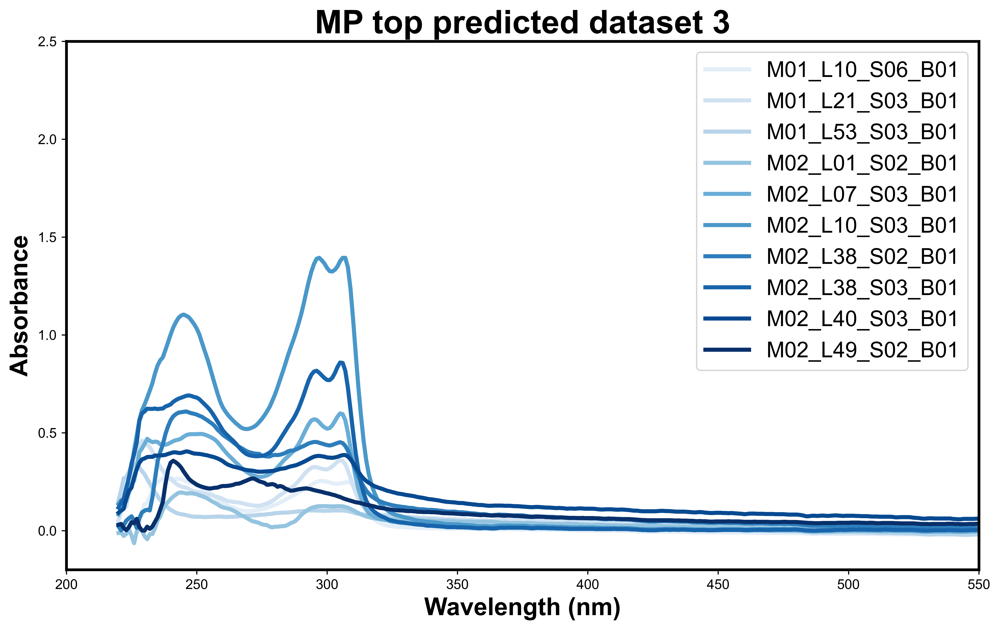

In [2]:
#top predictions from MP dataset 3

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L38_S02_B01",
          "M01_L21_S03_B01",
          "M02_L40_S03_B01",
          "M02_L38_S03_B01",
          "M02_L10_S03_B01",
          "M01_L53_S03_B01",
          "M02_L01_S02_B01",
          "M02_L07_S03_B01",
          "M02_L49_S02_B01",
          "M01_L10_S06_B01"]


plot_h5_blue_scheme(input_h5, example, title="MP top predicted dataset 3")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_58699/2215709403.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


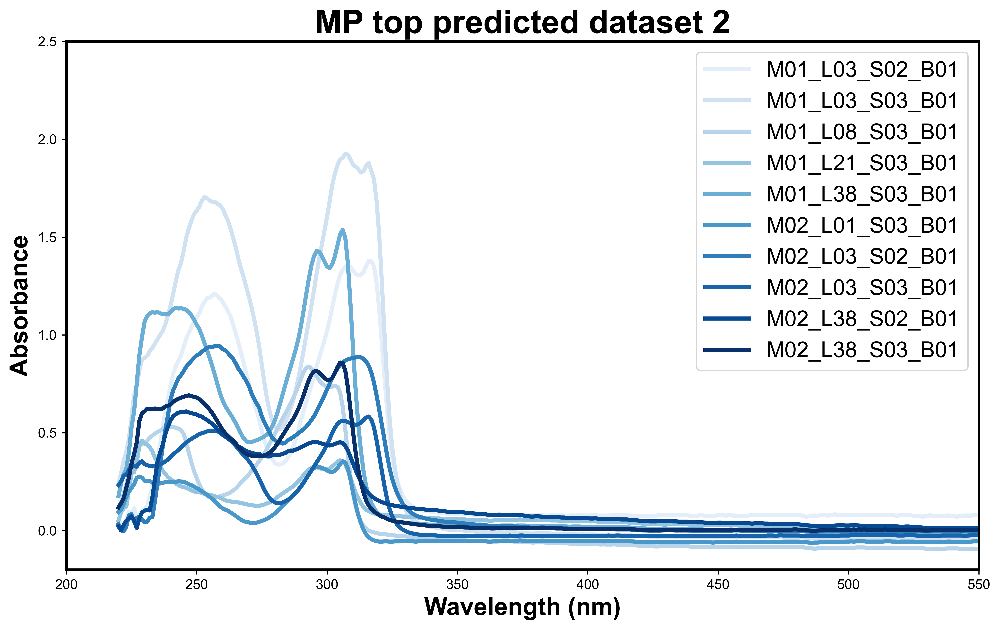

In [7]:
#top predictions from MP dataset 2

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L03_S03_B01",
          "M01_L03_S03_B01",
          "M01_L38_S03_B01",
          "M02_L01_S03_B01",
          "M02_L38_S03_B01",
          "M02_L03_S02_B01",
          "M01_L21_S03_B01",
          "M02_L38_S02_B01",
          "M01_L03_S02_B01",
          "M01_L08_S03_B01"]


plot_h5_blue_scheme(input_h5, example, title="MP top predicted dataset 2")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_58699/2215709403.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


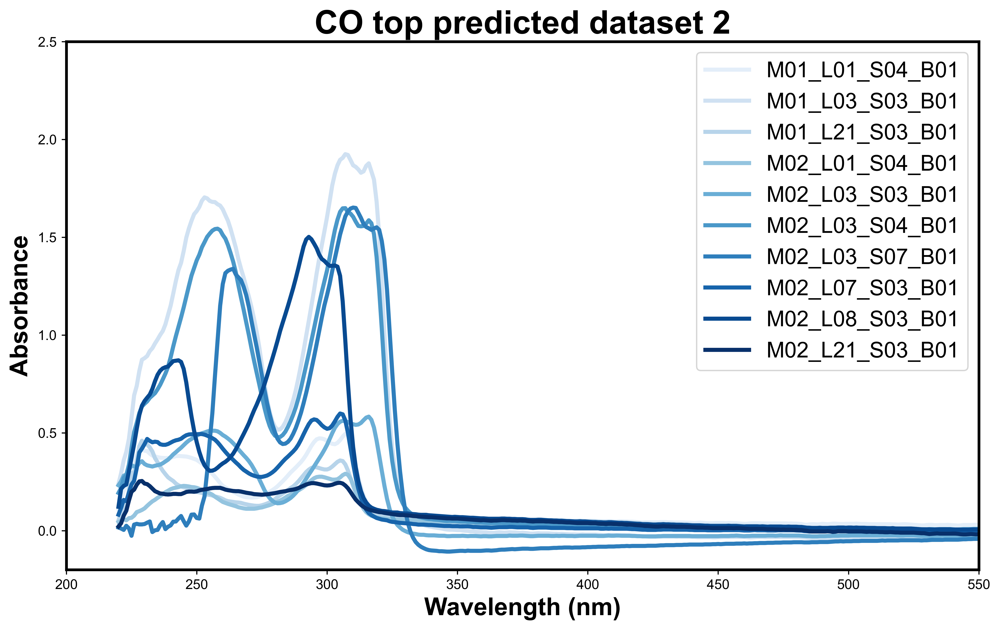

In [5]:
#top predictions from CO dataset 2

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L01_S04_B01",
          "M02_L03_S04_B01",
          "M02_L03_S03_B01",
          "M02_L21_S03_B01",
          "M02_L07_S03_B01",
          "M01_L03_S03_B01",
          "M01_L01_S04_B01",
          "M01_L21_S03_B01",
          "M02_L08_S03_B01",
          "M02_L03_S07_B01"]


plot_h5_blue_scheme(input_h5, example, title="CO top predicted dataset 2")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_58699/2215709403.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


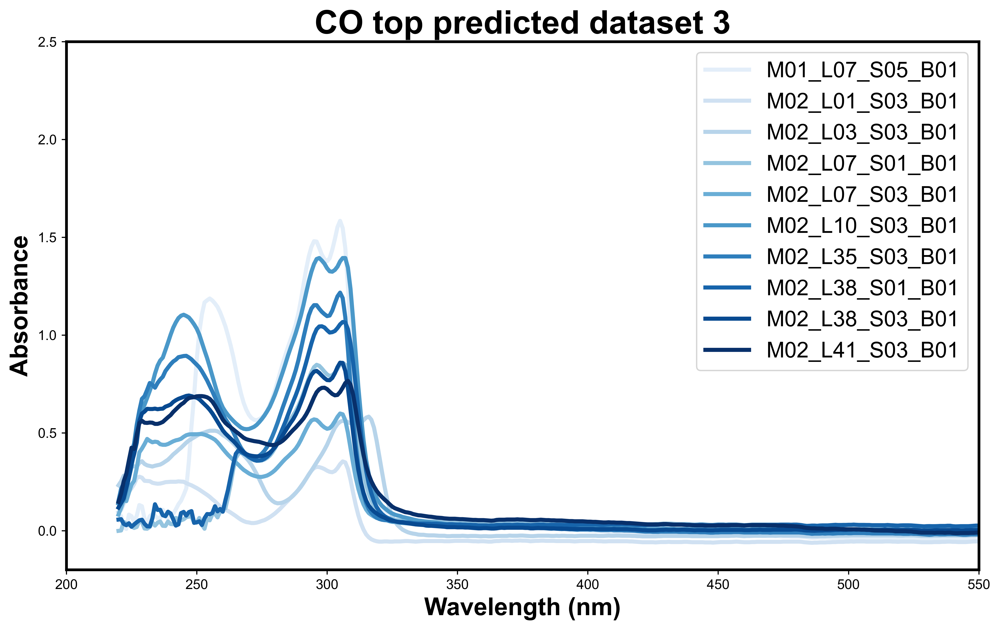

In [6]:
#top predictions from CO dataset 3

input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

example= ["M02_L07_S03_B01",
          "M02_L41_S03_B01",
          "M02_L38_S03_B01",
          "M02_L01_S03_B01",
          "M02_L35_S03_B01",
          "M02_L03_S03_B01",
          "M01_L07_S05_B01",
          "M02_L10_S03_B01",
          "M02_L07_S01_B01",
          "M02_L38_S01_B01"]


plot_h5_blue_scheme(input_h5, example, title="CO top predicted dataset 3")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


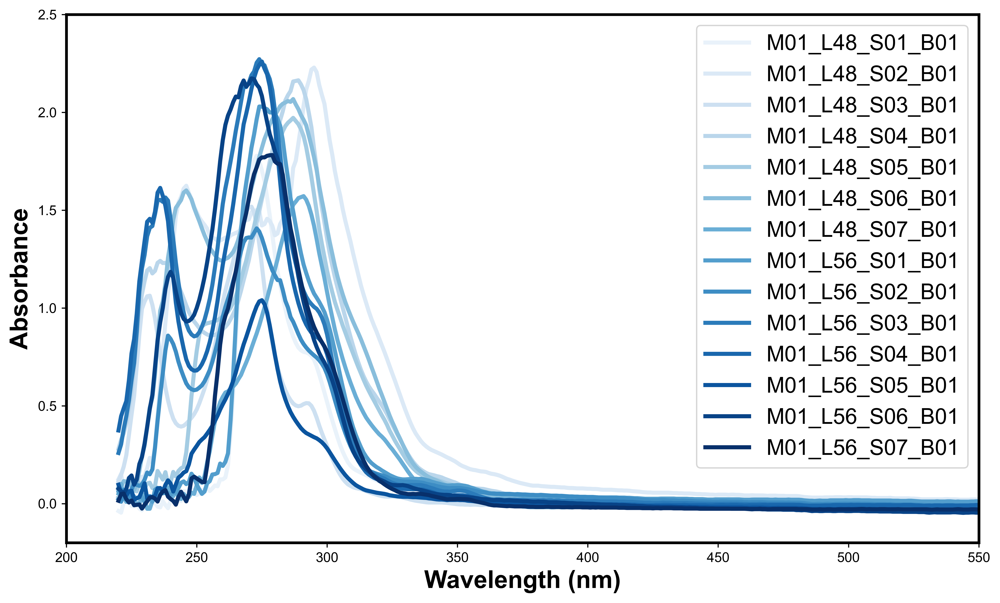

In [47]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= ["M01_L48_S01_B01", 
          "M01_L48_S02_B01",
          "M01_L48_S03_B01",
          "M01_L48_S04_B01",
          "M01_L48_S05_B01",
          "M01_L48_S06_B01",
          "M01_L48_S07_B01",
          "M01_L56_S01_B01", 
          "M01_L56_S02_B01",
          "M01_L56_S03_B01",
          "M01_L56_S04_B01",
          "M01_L56_S05_B01",
          "M01_L56_S06_B01",
          "M01_L56_S07_B01",]




plot_h5_blue_scheme(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


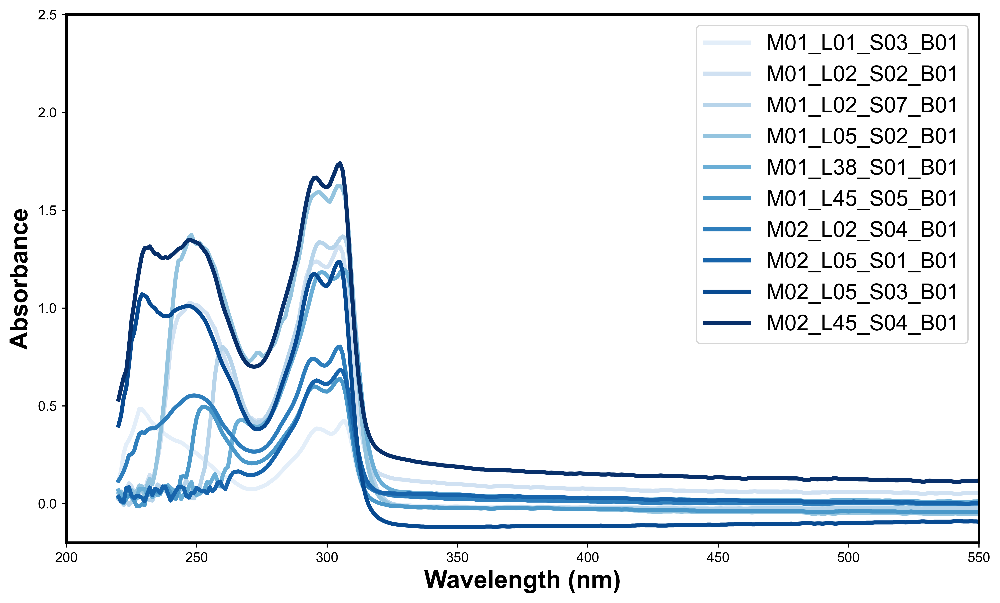

In [48]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= ["M01_L01_S03_B01",
#"M01_L02_S01_B01",
"M01_L02_S02_B01",
#"M01_L02_S03_B01",
#"M01_L02_S04_B01",
#"M01_L02_S05_B01",
"M01_L02_S07_B01",
#"M01_L05_S01_B01",
"M01_L05_S02_B01",
#"M01_L05_S03_B01",
#"M01_L05_S04_B01",
#"M01_L05_S05_B01",
#"M01_L05_S07_B01",
"M01_L45_S05_B01",
"M01_L38_S01_B01",
#"M02_L02_S01_B01",
#"M02_L02_S02_B01",
#"M02_L02_S03_B01",
"M02_L02_S04_B01",
#"M02_L02_S06_B01",
#"M02_L02_S07_B01",
"M02_L05_S01_B01",
#"M02_L05_S02_B01",
"M02_L05_S03_B01",
#"M02_L05_S04_B01",
#"M02_L05_S05_B01",
#"M02_L05_S06_B01",
#"M02_L05_S07_B01",
#"M02_L45_S03_B01",
"M02_L45_S04_B01",
         ]

plot_h5_blue_scheme(input_h5, example, title="")

In [49]:
input_h5 = "HDF5 Datasets/250708 - Training Dataset.h5"
output = "/Users/andytran/Desktop/poster plots"

example= [
          "M02_L02_S04_B01",
          "M02_L02_S05_B01",
          "M02_L02_S06_B01",
          "M02_L02_S07_B01",
         ]

plot_h5_blue_scheme(input_h5, output_file_path=output, target_spectra=example, title="")

Blue scheme plot saved: /Users/andytran/Desktop/poster plots/overlaid_spectra_blue.svg


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


In [50]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
output = "/Users/andytran/Desktop/poster plots"

example= [
    "M02_L07_S03_B01","M01_L35_S03_B01","M01_L07_S05_B01","M01_L35_S04_B01","M02_L38_S03_B01","M02_L41_S03_B01",
    "M02_L35_S03_B01","M01_L45_S04_B01","M02_L01_S03_B01","M02_L10_S03_B01"
         ]

plot_h5_blue_scheme(input_h5, output_file_path=output, target_spectra=example, title="")

Blue scheme plot saved: /Users/andytran/Desktop/poster plots/overlaid_spectra_blue.svg


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


In [51]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
output = "/Users/andytran/Desktop/poster plots"

example= [
    "M02_L40_S03_B01",
    "M02_L07_S03_B01",
    "M02_L41_S03_B01",
    "M01_L47_S04_B01",
    "M02_L55_S03_B01",
    "M02_L55_S04_B01",
    "M02_L38_S03_B01",
    "M02_L10_S03_B01",
    "M02_L35_S03_B01",
    "M01_L21_S04_B01",
         ]

plot_h5_blue_scheme(input_h5, output_file_path=output, target_spectra=example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


Blue scheme plot saved: /Users/andytran/Desktop/poster plots/overlaid_spectra_blue.svg


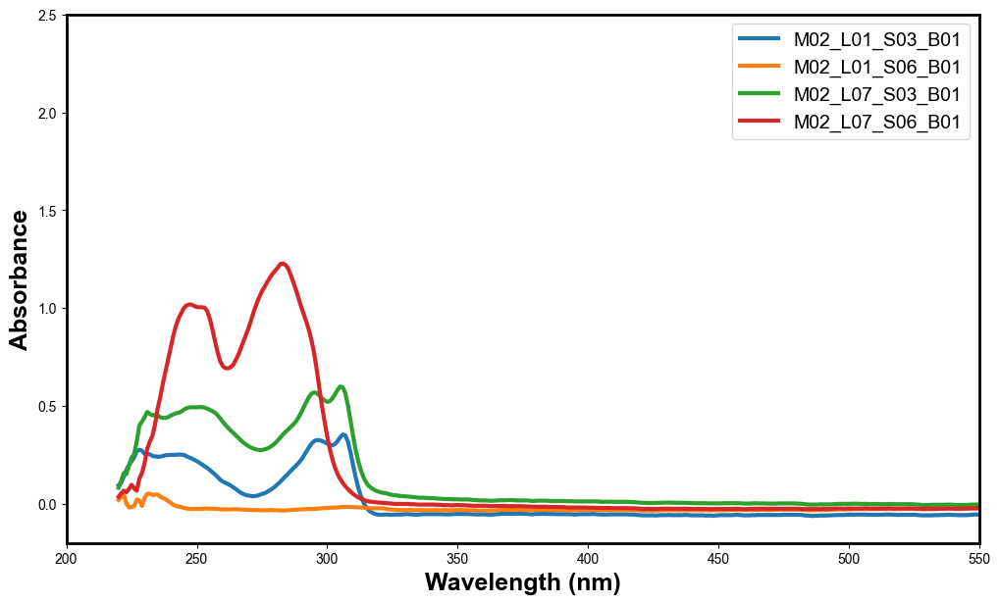

In [52]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= [
          "M02_L07_S03_B01",

          "M02_L01_S03_B01",

          "M02_L07_S06_B01",

          "M02_L01_S06_B01",
         ]

plot_h5(input_h5, example, title="")

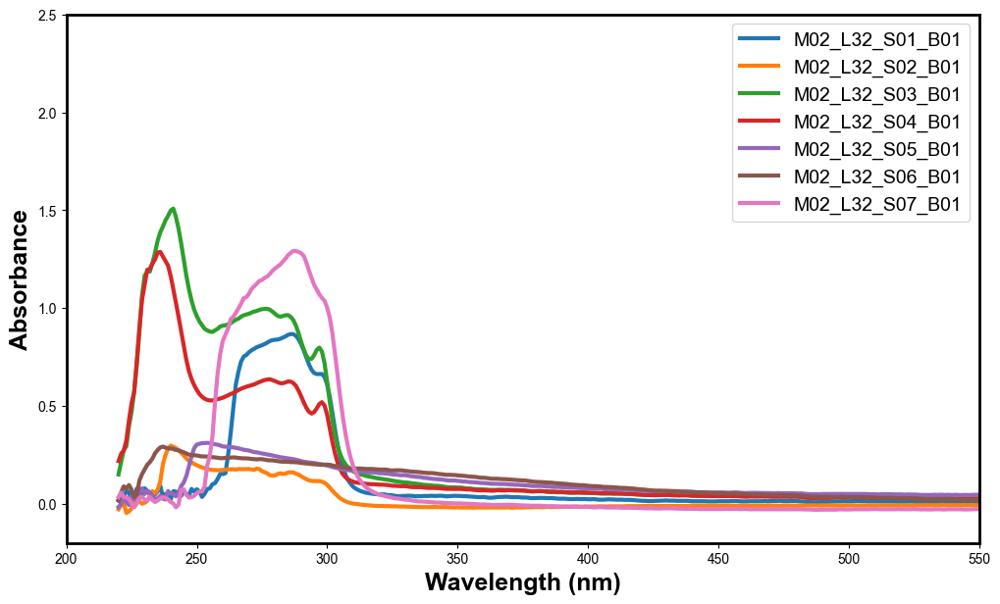

In [53]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= [
          "M02_L32_S01_B01",
          "M02_L32_S02_B01",
          "M02_L32_S03_B01",
          "M02_L32_S04_B01",
          "M02_L32_S05_B01",
          "M02_L32_S06_B01",
          "M02_L32_S07_B01",
         ]

plot_h5(input_h5, example, title="")

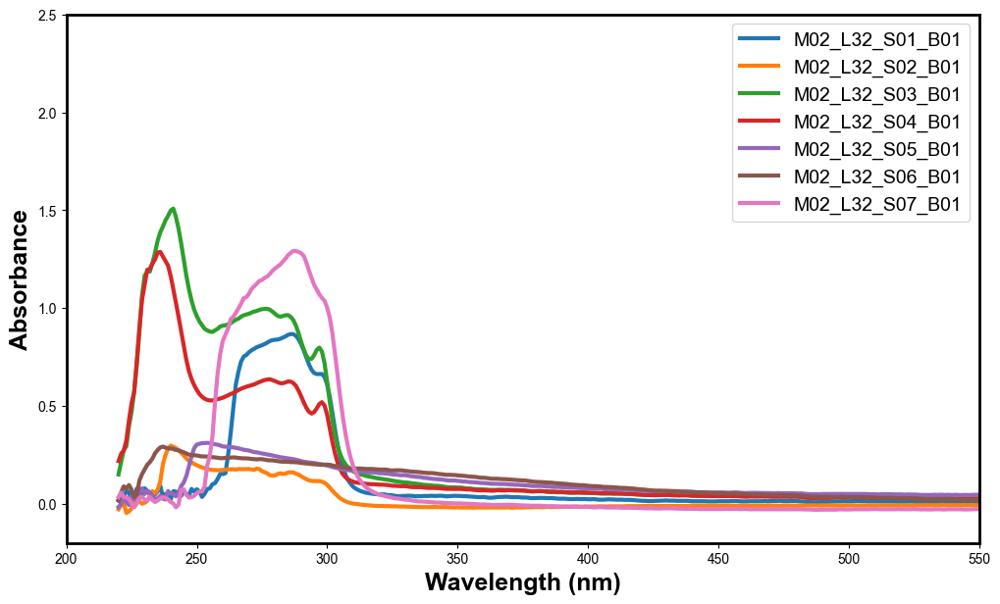

In [54]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= ["M02_L32_S01_B01",
          "M02_L32_S02_B01",
          "M02_L32_S03_B01",
          "M02_L32_S04_B01",
          "M02_L32_S05_B01",
          "M02_L32_S06_B01",
          "M02_L32_S07_B01",]

example_no2 = ["M01_L32_S01_B01",
          "M02_L32_S02_B01",
          "M02_L32_S03_B01",
          "M02_L32_S04_B01",
          "M02_L32_S05_B01",
          "M02_L32_S06_B01",
          "M02_L32_S07_B01",]

plot_h5(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/89470574.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


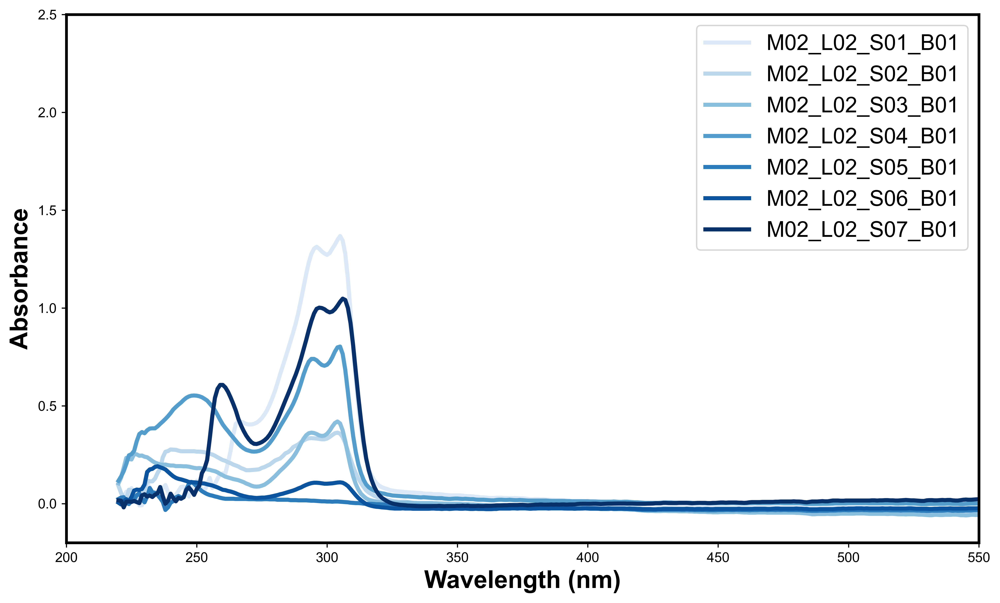

In [55]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"


example= ["M02_L02_S01_B01",
          "M02_L02_S02_B01",
          "M02_L02_S03_B01",
          "M02_L02_S04_B01",
          "M02_L02_S05_B01",
          "M02_L02_S06_B01",
          "M02_L02_S07_B01",]

plot_h5_blue_scheme(input_h5, example, title="")

In [17]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

top_CO_df = pd.read_csv("Autogluon Predictions/CO Dataset 4 predictions.csv").head(10)  # top 10 predictions

top_CO = top_CO_df["Dataset"].tolist()

plot_h5(input_h5, top_CO, title="")

FileNotFoundError: [Errno 2] No such file or directory: 'Autogluon Predictions/CO_ds4_predictions.csv'

In [ ]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"

top_MP_df = pd.read_csv("Autogluon Predictions/MP Dataset 4 predictions.csv").head(10)  # top 10 predictions

top_MP = top_MP_df["Dataset"].tolist()

plot_h5(input_h5, top_MP, title="")

FileNotFoundError: [Errno 2] No such file or directory: 'Autogluon Predictions/MP_ds4_predictions.csv'

## Plotting UV-Vis of sample with control using plot_h5_controls()

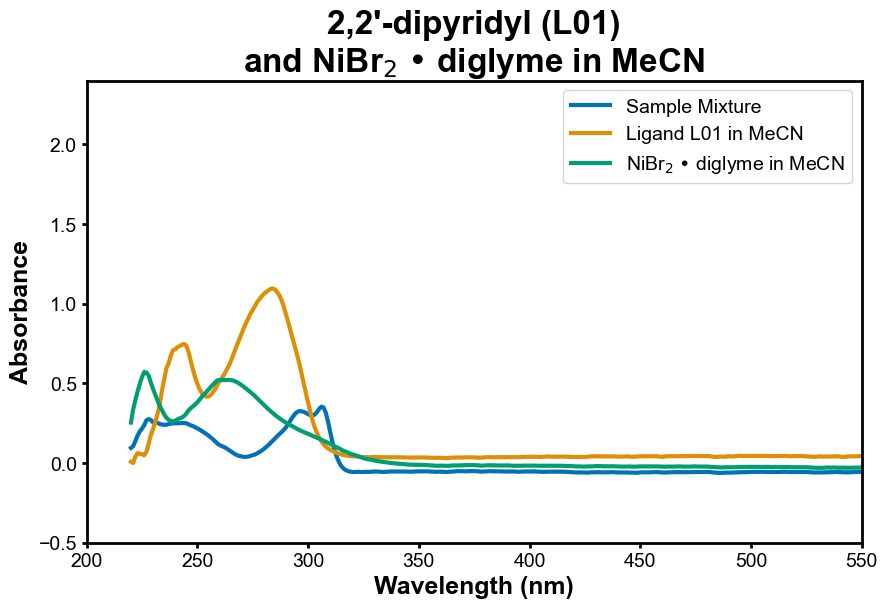

In [ ]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
controls_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library Controls.h5"

target = "M02_L01_S03_B01"

plot_h5_controls(input_h5, controls_h5, target_spectra=target)

In [ ]:
# Plotting for Nickel Ligation Library

control_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library Controls.h5"
plot_output = "UV-Vis/UV-Vis Spectra"
plot_h5_controls(input_h5, control_h5, output_file_path = plot_output)

Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S01_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S01_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S01_B03.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S02_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S02_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S02_B03.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S03_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S03_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S03_B03.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S04_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S04_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S04_B03.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S05_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S05_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S05_B03.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S06_B01.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S06_B02.png
Plot saved: UV-Vis/UV-Vis Spectra/M01_L01_S06_B03.png
Plot saved: UV-Vis/UV-Vis Sp

# Plotting UV-Vis time course

In [63]:

def plot_h5_blue_scheme_time_course(h5_file_path, target_spectra=None, output_file_path=None, title=None):
    """
    Plots absorbance spectra from an HDF5 file using a blue color scheme.

    Parameters:
        h5_file_path (str): Path to the HDF5 file.
        target_spectra (str or list of str, optional): Spectra identifiers to match. 
            If None, plots all datasets.
        output_file_path (str, optional): If given, saves the plot to this folder; otherwise, displays it.
        title (str, optional): Title for the plot. If None, a default title is used based on the dataset attributes.

    Returns:
        None
    """
    try:
        if isinstance(target_spectra, str):
            target_spectra = [target_spectra]

        with h5py.File(h5_file_path, 'r') as hdf:
            if target_spectra:
                matching_datasets = [name for name in target_spectra if name in hdf.keys()]
            else:
                matching_datasets = list(hdf.keys())

            if not matching_datasets:
                print(f"No datasets matched the specified criteria.")
                return

            # Set up the color palette using Blues
            cmap = get_cmap("Blues")
            num_colors = len(matching_datasets)
            colors = [cmap(i / max(num_colors, 1)) for i in range(1, num_colors + 1)]

            # Create a figure for overlay
            plt.figure(figsize=(12, 7),dpi=600)

            for idx, dataset_name in enumerate(matching_datasets):
                dataset = hdf[dataset_name]
                data = dataset[:]
                wavelengths = data[:, 0]
                absorbances = data[:, 1]

                label = f"{dataset_name}"
                plt.plot(
                    wavelengths,
                    absorbances,
                    linewidth=3.0,
                    label=label,
                    color=colors[idx]
                )

            # Plot styling
            plt.title(title, fontsize=24)
            plt.xlabel("Wavelength (nm)", fontsize=18)
            plt.ylabel("Absorbance", fontsize=18)
            plt.legend(fontsize=16)
            plt.grid(False)
            plt.xlim(200, 550)
            plt.ylim(-0.2, 2.5)

            if output_file_path:
                os.makedirs(output_file_path, exist_ok=True)
                output_file = os.path.join(output_file_path, "overlaid_spectra_blue.svg")
                plt.savefig(output_file, bbox_inches='tight')
                print(f"Blue scheme plot saved: {output_file}")
            else:
                plt.show()

            plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


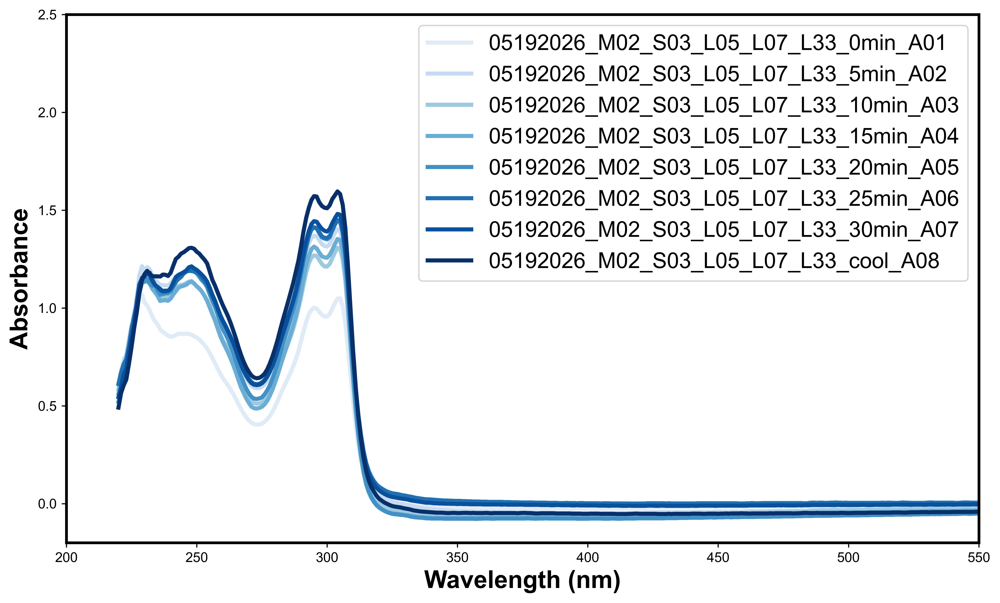

In [ ]:
input_h5 = "UV-Vis Time Course/UV-Vis Time Course.h5"

# dtbbpy in MeCN
example= ["05192026_M02_S03_L05_L07_L33_0min_A01", 
          "05192026_M02_S03_L05_L07_L33_5min_A02",
          "05192026_M02_S03_L05_L07_L33_10min_A03",
          "05192026_M02_S03_L05_L07_L33_15min_A04",
          "05192026_M02_S03_L05_L07_L33_20min_A05",
          "05192026_M02_S03_L05_L07_L33_25min_A06",
          "05192026_M02_S03_L05_L07_L33_30min_A07",
          "05192026_M02_S03_L05_L07_L33_cool_A08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


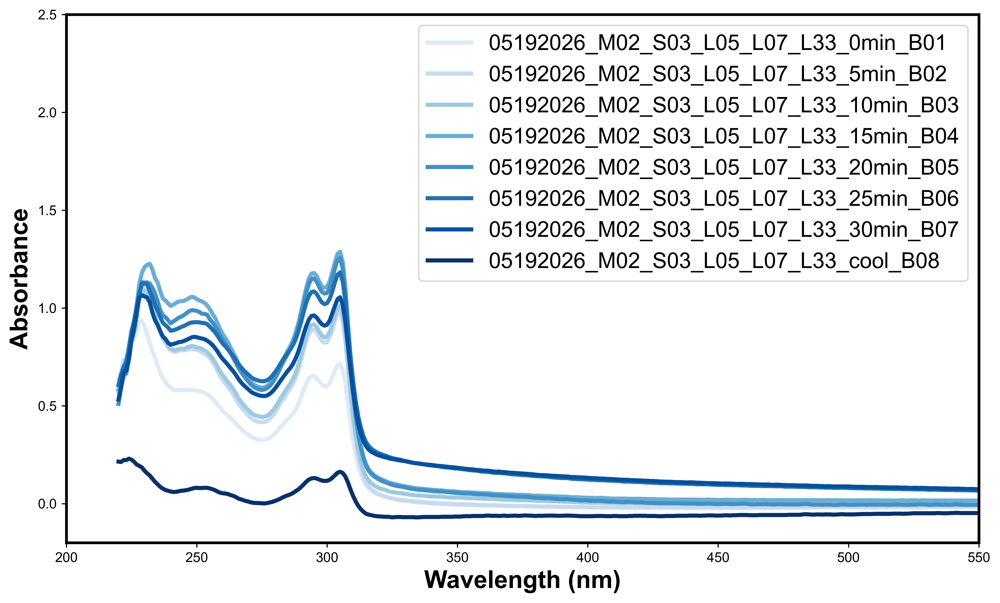

In [ ]:
# Dichloro in MeCN
example= ["05192026_M02_S03_L05_L07_L33_0min_B01", 
          "05192026_M02_S03_L05_L07_L33_5min_B02",
          "05192026_M02_S03_L05_L07_L33_10min_B03",
          "05192026_M02_S03_L05_L07_L33_15min_B04",
          "05192026_M02_S03_L05_L07_L33_20min_B05",
          "05192026_M02_S03_L05_L07_L33_25min_B06",
          "05192026_M02_S03_L05_L07_L33_30min_B07",
          "05192026_M02_S03_L05_L07_L33_cool_B08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


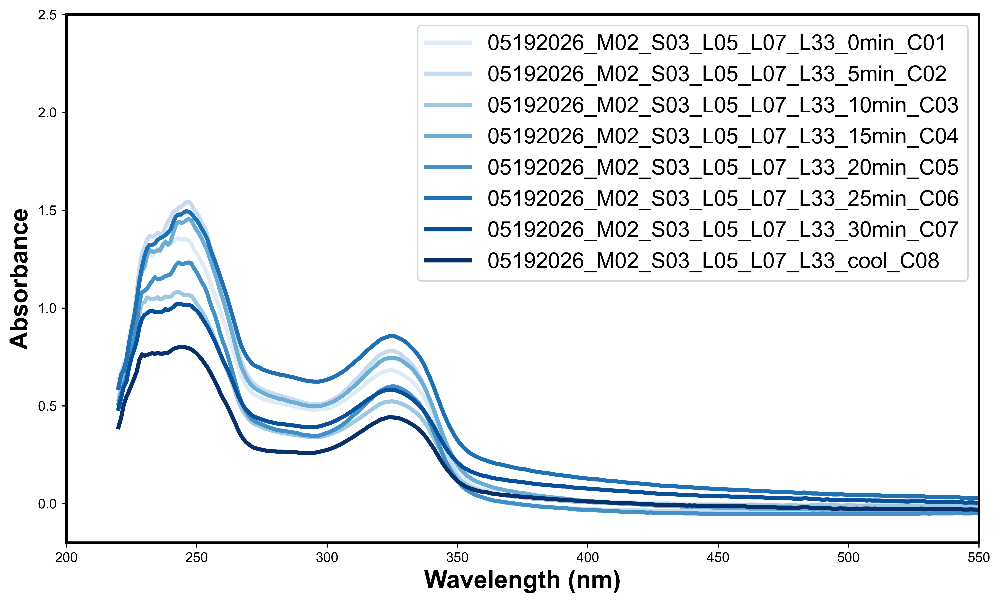

In [ ]:
# Dinitro in MeCN
example= ["05192026_M02_S03_L05_L07_L33_0min_C01", 
          "05192026_M02_S03_L05_L07_L33_5min_C02",
          "05192026_M02_S03_L05_L07_L33_10min_C03",
          "05192026_M02_S03_L05_L07_L33_15min_C04",
          "05192026_M02_S03_L05_L07_L33_20min_C05",
          "05192026_M02_S03_L05_L07_L33_25min_C06",
          "05192026_M02_S03_L05_L07_L33_30min_C07",
          "05192026_M02_S03_L05_L07_L33_cool_C08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


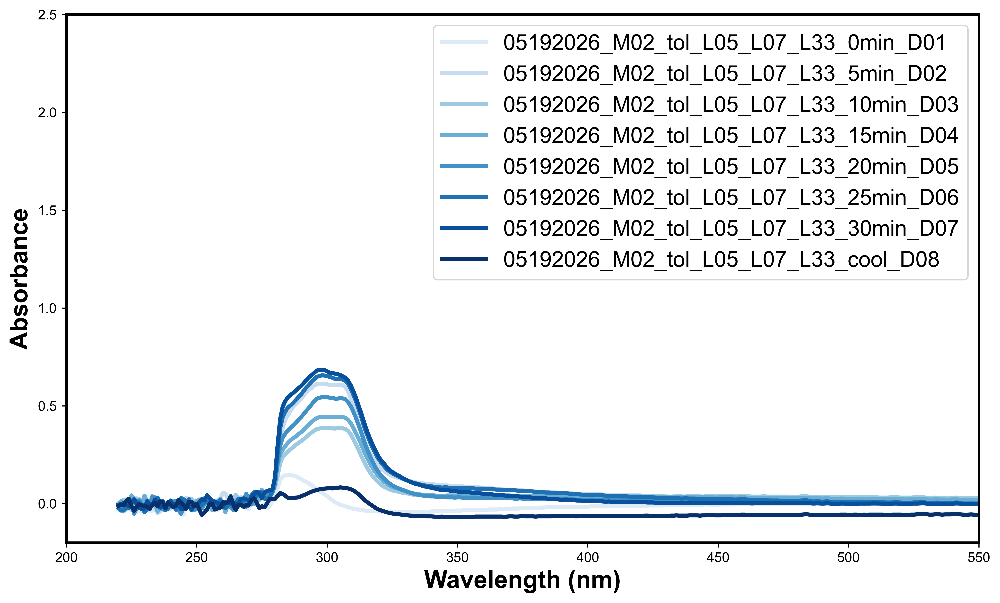

In [ ]:
# dtbbpy in tol
example= ["05192026_M02_tol_L05_L07_L33_0min_D01", 
          "05192026_M02_tol_L05_L07_L33_5min_D02",
          "05192026_M02_tol_L05_L07_L33_10min_D03",
          "05192026_M02_tol_L05_L07_L33_15min_D04",
          "05192026_M02_tol_L05_L07_L33_20min_D05",
          "05192026_M02_tol_L05_L07_L33_25min_D06",
          "05192026_M02_tol_L05_L07_L33_30min_D07",
          "05192026_M02_tol_L05_L07_L33_cool_D08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


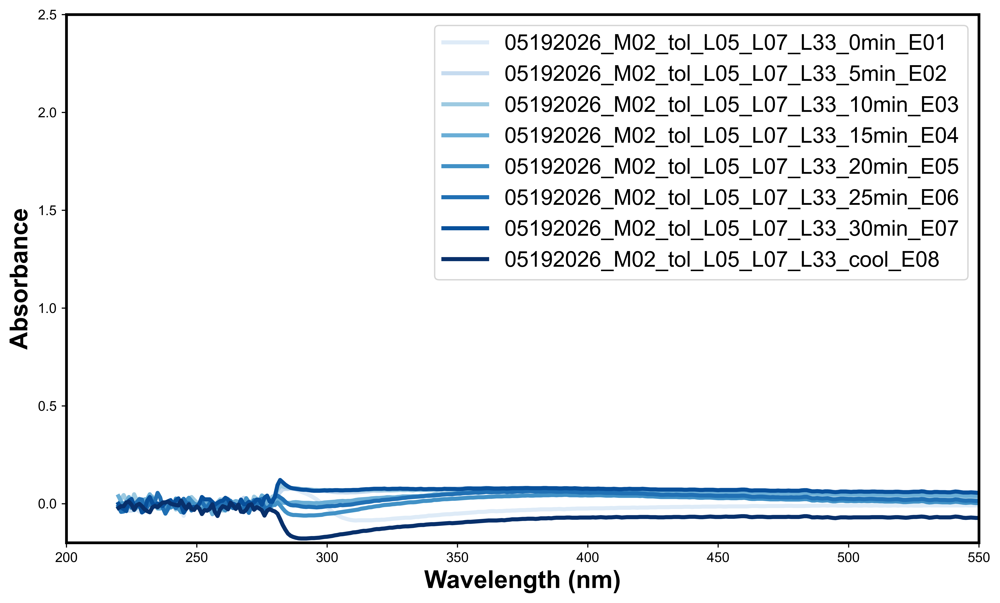

In [ ]:
# dichloro in tol
example= ["05192026_M02_tol_L05_L07_L33_0min_E01", 
          "05192026_M02_tol_L05_L07_L33_5min_E02",
          "05192026_M02_tol_L05_L07_L33_10min_E03",
          "05192026_M02_tol_L05_L07_L33_15min_E04",
          "05192026_M02_tol_L05_L07_L33_20min_E05",
          "05192026_M02_tol_L05_L07_L33_25min_E06",
          "05192026_M02_tol_L05_L07_L33_30min_E07",
          "05192026_M02_tol_L05_L07_L33_cool_E08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


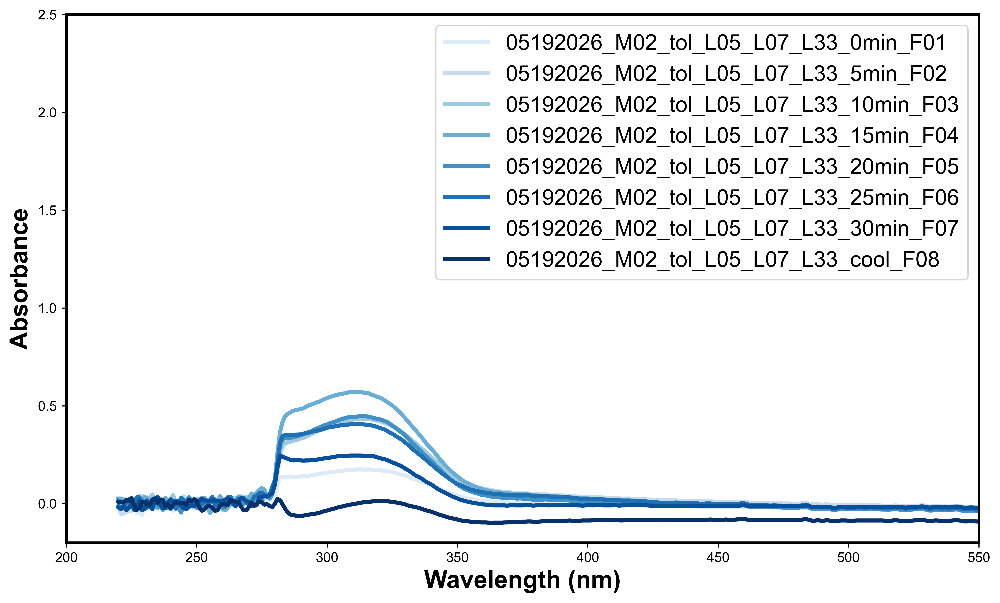

In [ ]:
# dinitro in tol
example= ["05192026_M02_tol_L05_L07_L33_0min_F01", 
          "05192026_M02_tol_L05_L07_L33_5min_F02",
          "05192026_M02_tol_L05_L07_L33_10min_F03",
          "05192026_M02_tol_L05_L07_L33_15min_F04",
          "05192026_M02_tol_L05_L07_L33_20min_F05",
          "05192026_M02_tol_L05_L07_L33_25min_F06",
          "05192026_M02_tol_L05_L07_L33_30min_F07",
          "05192026_M02_tol_L05_L07_L33_cool_F08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


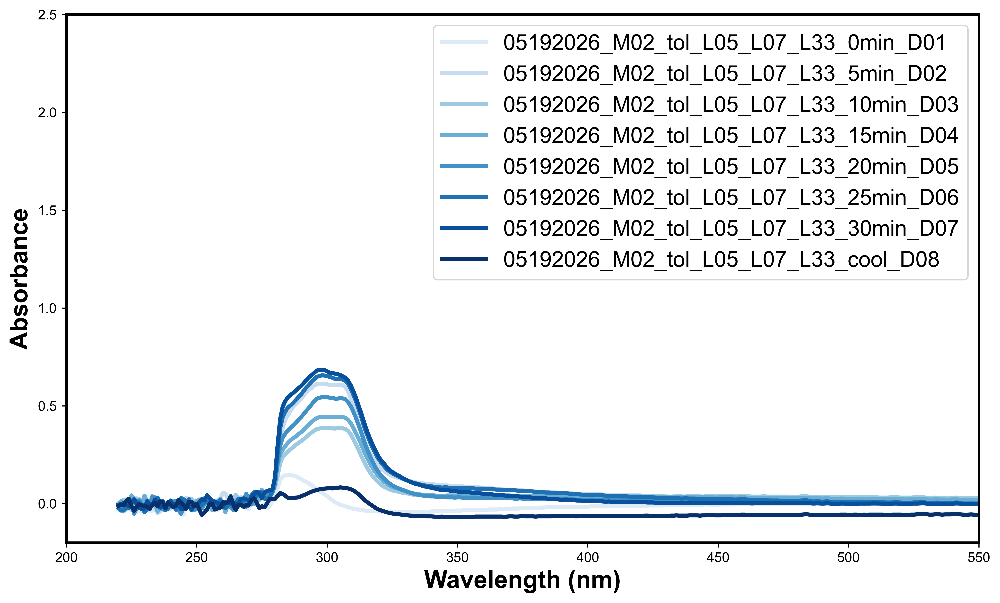

In [ ]:
# dtbbpy in tol
example= ["05192026_M02_tol_L05_L07_L33_0min_D01",
          "05192026_M02_tol_L05_L07_L33_5min_D02",
          "05192026_M02_tol_L05_L07_L33_10min_D03",
          "05192026_M02_tol_L05_L07_L33_15min_D04",
          "05192026_M02_tol_L05_L07_L33_20min_D05",
          "05192026_M02_tol_L05_L07_L33_25min_D06",
          "05192026_M02_tol_L05_L07_L33_30min_D07",
          "05192026_M02_tol_L05_L07_L33_cool_D08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


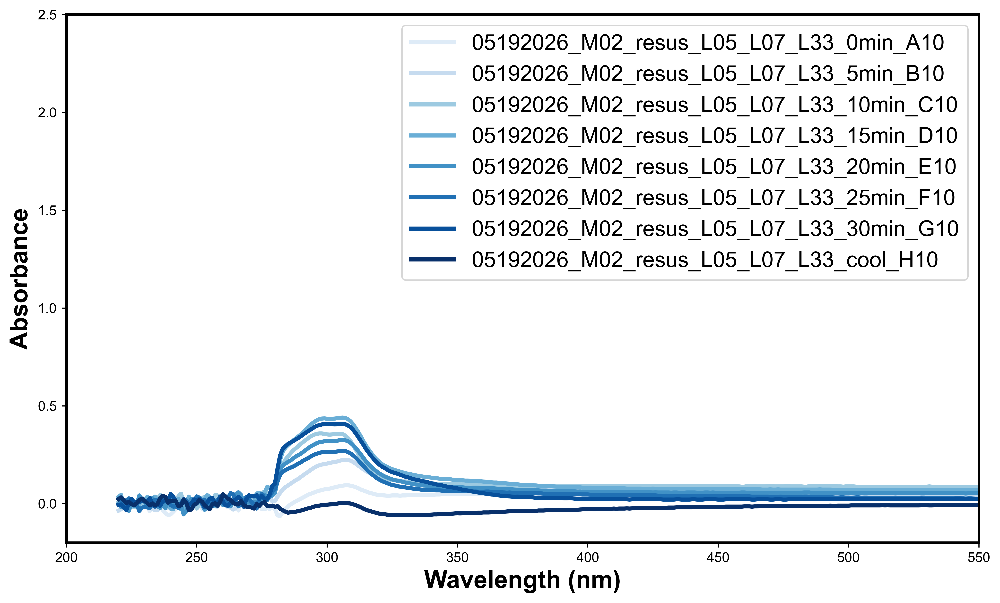

In [ ]:
# dtbbpy in tol
example= ["05192026_M02_resus_L05_L07_L33_0min_A10",
          "05192026_M02_resus_L05_L07_L33_5min_B10",
          "05192026_M02_resus_L05_L07_L33_10min_C10",
          "05192026_M02_resus_L05_L07_L33_15min_D10",
          "05192026_M02_resus_L05_L07_L33_20min_E10",
          "05192026_M02_resus_L05_L07_L33_25min_F10",
          "05192026_M02_resus_L05_L07_L33_30min_G10",
          "05192026_M02_resus_L05_L07_L33_cool_H10",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


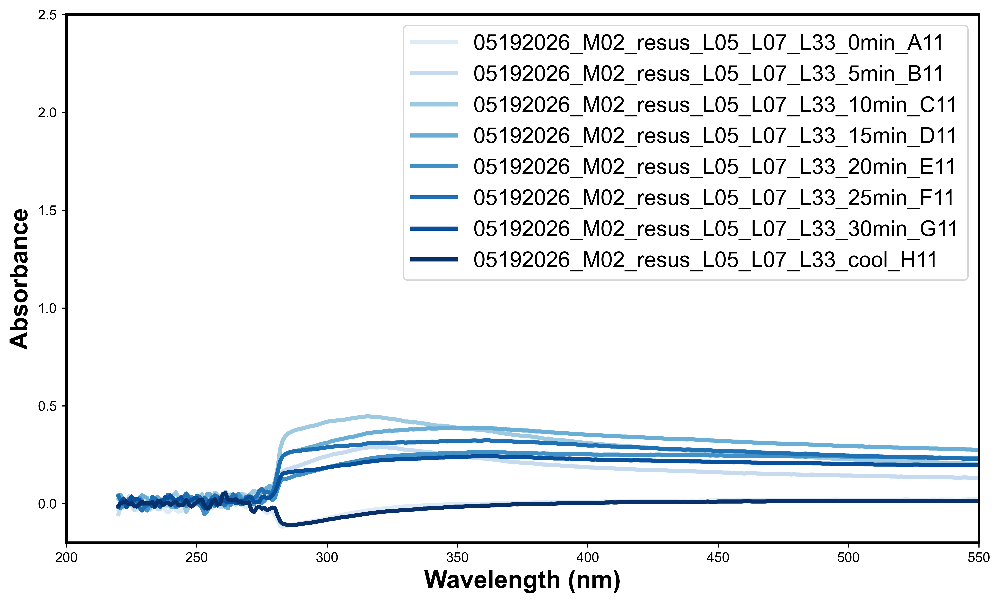

In [ ]:
# dichloro in tol
example= ["05192026_M02_resus_L05_L07_L33_0min_A11",
          "05192026_M02_resus_L05_L07_L33_5min_B11",
          "05192026_M02_resus_L05_L07_L33_10min_C11",
          "05192026_M02_resus_L05_L07_L33_15min_D11",
          "05192026_M02_resus_L05_L07_L33_20min_E11",
          "05192026_M02_resus_L05_L07_L33_25min_F11",
          "05192026_M02_resus_L05_L07_L33_30min_G11",
          "05192026_M02_resus_L05_L07_L33_cool_H11",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_93799/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


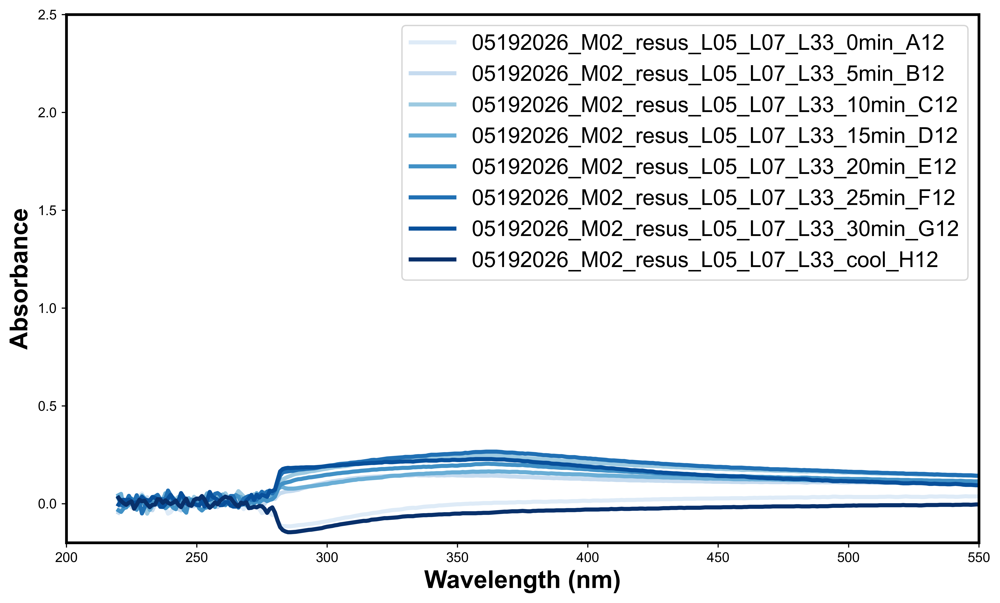

In [ ]:
# dinitro in tol
example= ["05192026_M02_resus_L05_L07_L33_0min_A12",
          "05192026_M02_resus_L05_L07_L33_5min_B12",
          "05192026_M02_resus_L05_L07_L33_10min_C12",
          "05192026_M02_resus_L05_L07_L33_15min_D12",
          "05192026_M02_resus_L05_L07_L33_20min_E12",
          "05192026_M02_resus_L05_L07_L33_25min_F12",
          "05192026_M02_resus_L05_L07_L33_30min_G12",
          "05192026_M02_resus_L05_L07_L33_cool_H12",
          ]

plot_h5_blue_scheme_time_course(input_h5, example, title="")

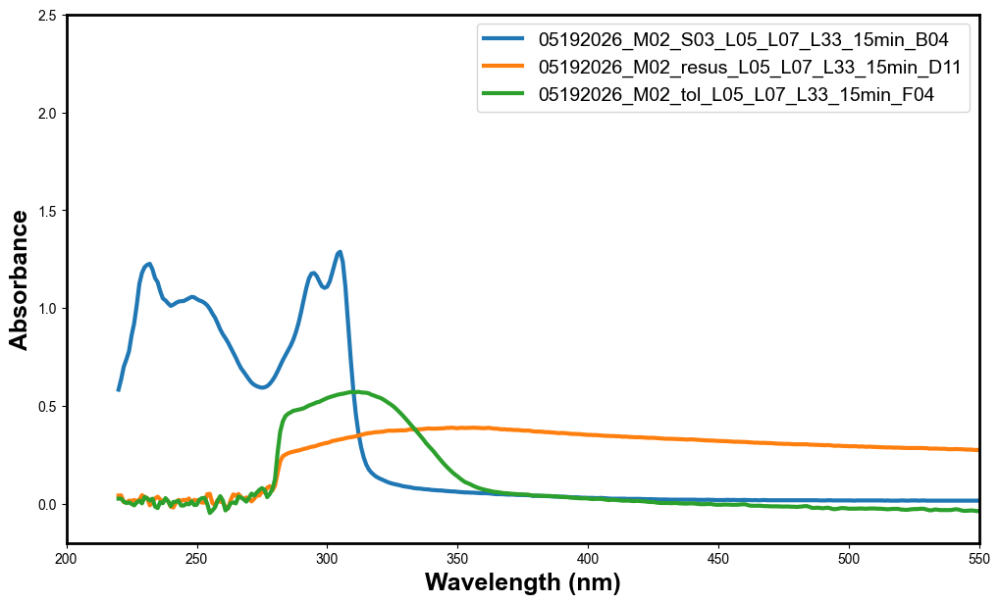

In [ ]:
# dichloro at 15 mins
# (1) MeCN prestir, UV-Vis in MeCN
# (2) Tol prestir, UV-Vis in Tol
# (3) Prestir in MeCN, UV-Vis in Tol

example= ["05192026_M02_S03_L05_L07_L33_15min_B04",
          "05192026_M02_tol_L05_L07_L33_15min_F04",
          "05192026_M02_resus_L05_L07_L33_15min_D11",
          
          ]

plot_h5(input_h5, example)

## UV-Vis time course 2

In [53]:
input_h5 = "UV-Vis Time Course/UV-Vis Time Course 2.h5"

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


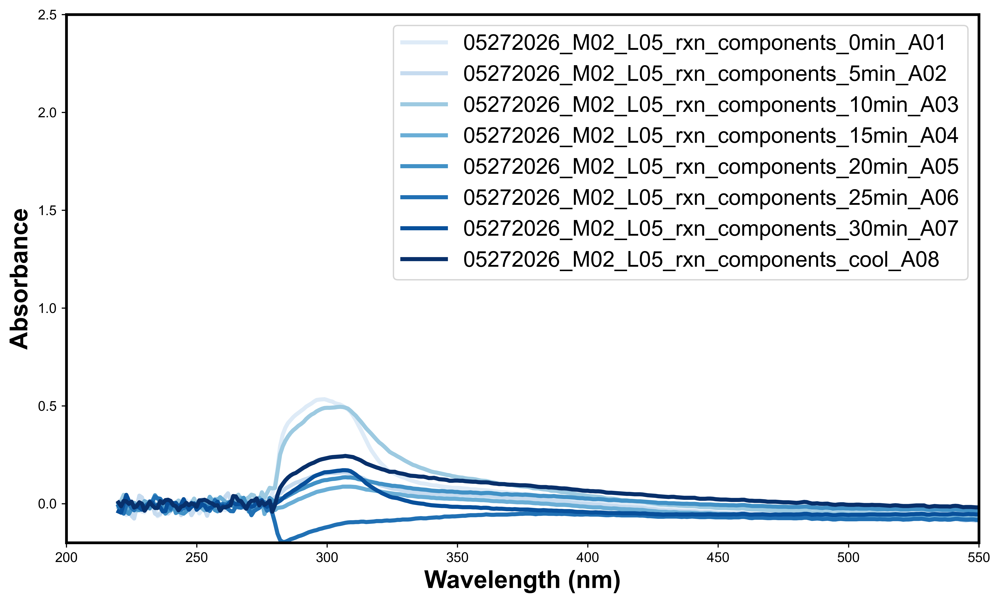

In [ ]:
# dtbbpyNiBr2 over 30 mins

example= ["05272026_M02_L05_rxn_components_0min_A01",
          "05272026_M02_L05_rxn_components_5min_A02",
          "05272026_M02_L05_rxn_components_10min_A03",
          "05272026_M02_L05_rxn_components_15min_A04",
          "05272026_M02_L05_rxn_components_20min_A05",
          "05272026_M02_L05_rxn_components_25min_A06",
          "05272026_M02_L05_rxn_components_30min_A07",
          "05272026_M02_L05_rxn_components_cool_A08",
          
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_29829/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


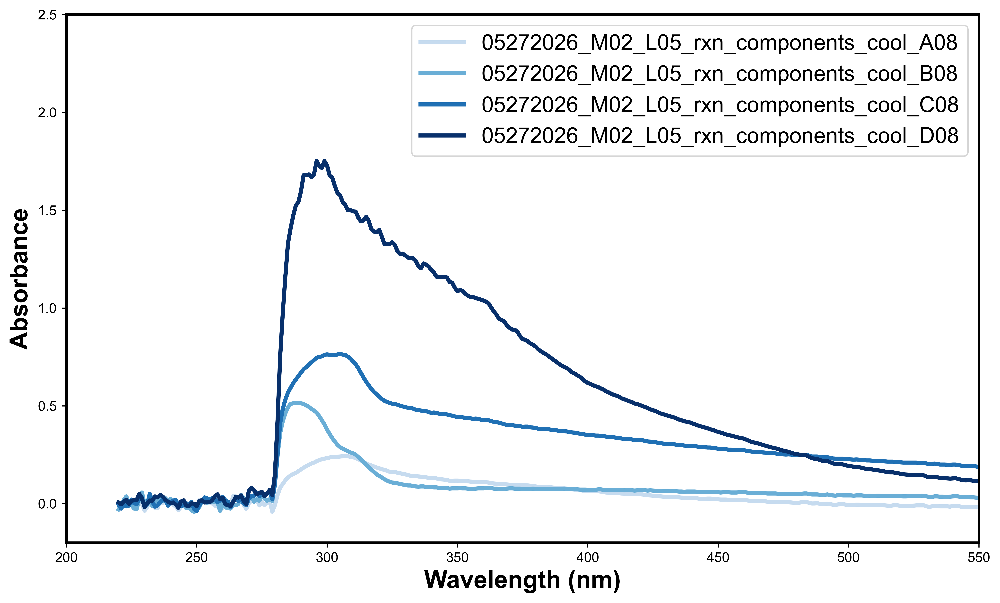

In [64]:
# dtbbpyNiBr2 + base over 30 mins

example= ["05272026_M02_L05_rxn_components_cool_A08",
          "05272026_M02_L05_rxn_components_cool_B08",
          "05272026_M02_L05_rxn_components_cool_C08",
          "05272026_M02_L05_rxn_components_cool_D08"
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


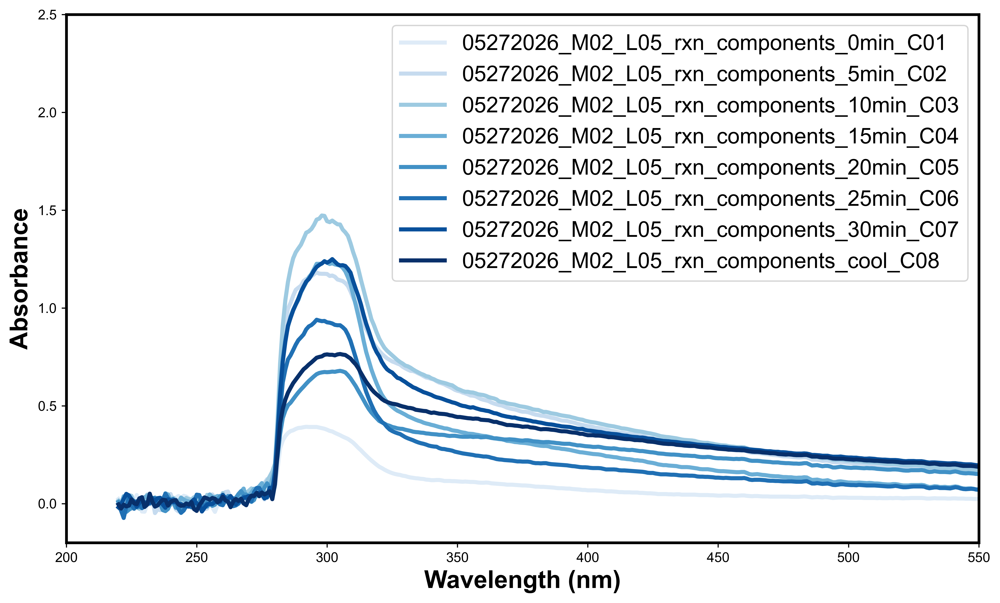

In [ ]:
# dtbbpyNiBr2 + silane over 30 mins

example= ["05272026_M02_L05_rxn_components_0min_C01",
          "05272026_M02_L05_rxn_components_5min_C02",
          "05272026_M02_L05_rxn_components_10min_C03",
          "05272026_M02_L05_rxn_components_15min_C04",
          "05272026_M02_L05_rxn_components_20min_C05",
          "05272026_M02_L05_rxn_components_25min_C06",
          "05272026_M02_L05_rxn_components_30min_C07",
          "05272026_M02_L05_rxn_components_cool_C08",
          
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


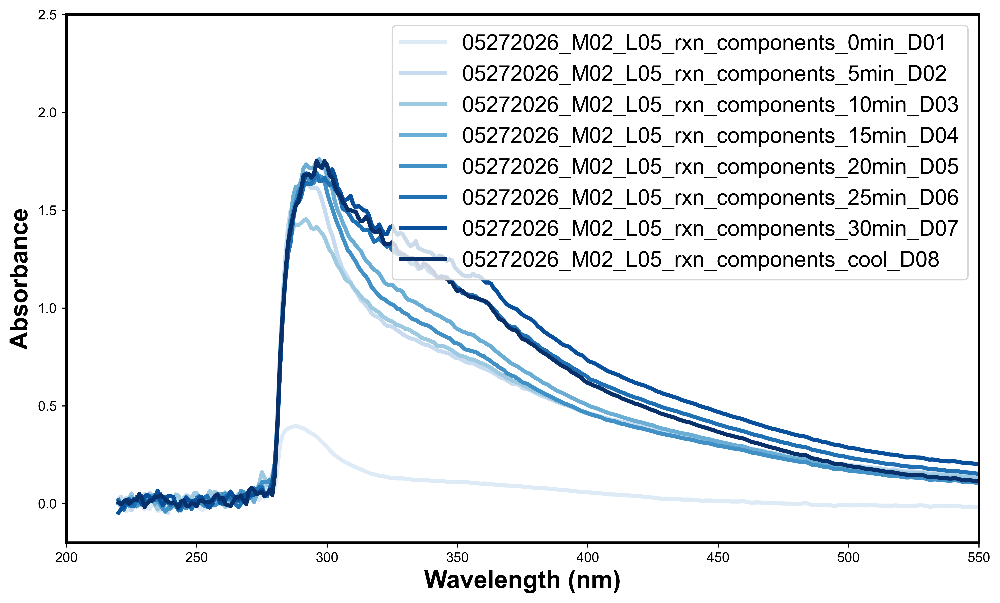

In [ ]:
# dtbbpyNiBr2 + base + silane over 30 mins

example= ["05272026_M02_L05_rxn_components_0min_D01",
          "05272026_M02_L05_rxn_components_5min_D02",
          "05272026_M02_L05_rxn_components_10min_D03",
          "05272026_M02_L05_rxn_components_15min_D04",
          "05272026_M02_L05_rxn_components_20min_D05",
          "05272026_M02_L05_rxn_components_25min_D06",
          "05272026_M02_L05_rxn_components_30min_D07",
          "05272026_M02_L05_rxn_components_cool_D08",
          
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


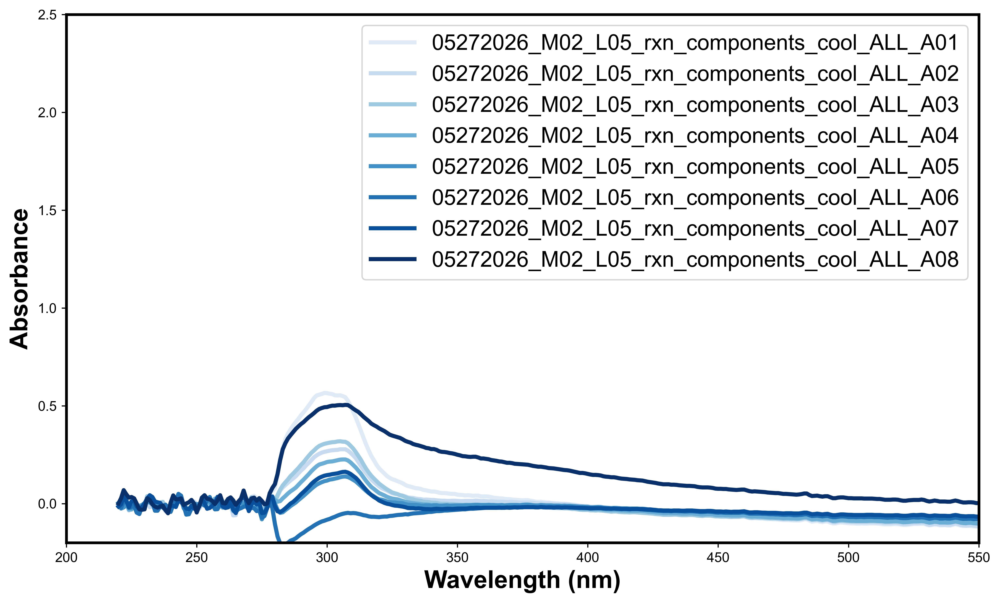

In [ ]:
# after cooling
# dtbbpyNiBr2 over 30 mins

example= ["05272026_M02_L05_rxn_components_cool_ALL_A01",
          "05272026_M02_L05_rxn_components_cool_ALL_A02",
          "05272026_M02_L05_rxn_components_cool_ALL_A03",
          "05272026_M02_L05_rxn_components_cool_ALL_A04",
          "05272026_M02_L05_rxn_components_cool_ALL_A05",
          "05272026_M02_L05_rxn_components_cool_ALL_A06",
          "05272026_M02_L05_rxn_components_cool_ALL_A07",
          "05272026_M02_L05_rxn_components_cool_ALL_A08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


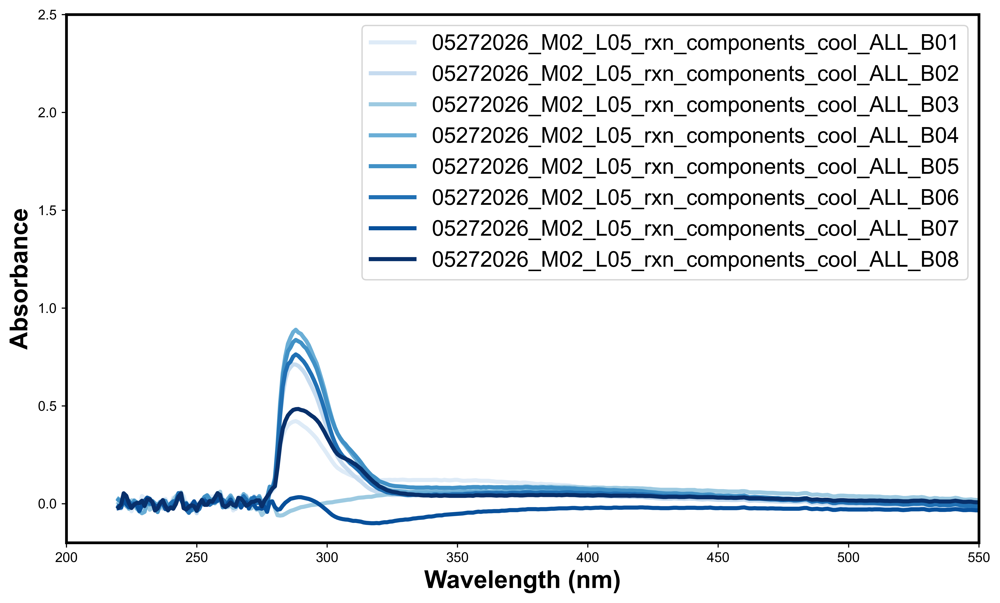

In [ ]:
# after cooling
# dtbbpyNiBr2 + base

example= ["05272026_M02_L05_rxn_components_cool_ALL_B01",
          "05272026_M02_L05_rxn_components_cool_ALL_B02",
          "05272026_M02_L05_rxn_components_cool_ALL_B03",
          "05272026_M02_L05_rxn_components_cool_ALL_B04",
          "05272026_M02_L05_rxn_components_cool_ALL_B05",
          "05272026_M02_L05_rxn_components_cool_ALL_B06",
          "05272026_M02_L05_rxn_components_cool_ALL_B07",
          "05272026_M02_L05_rxn_components_cool_ALL_B08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


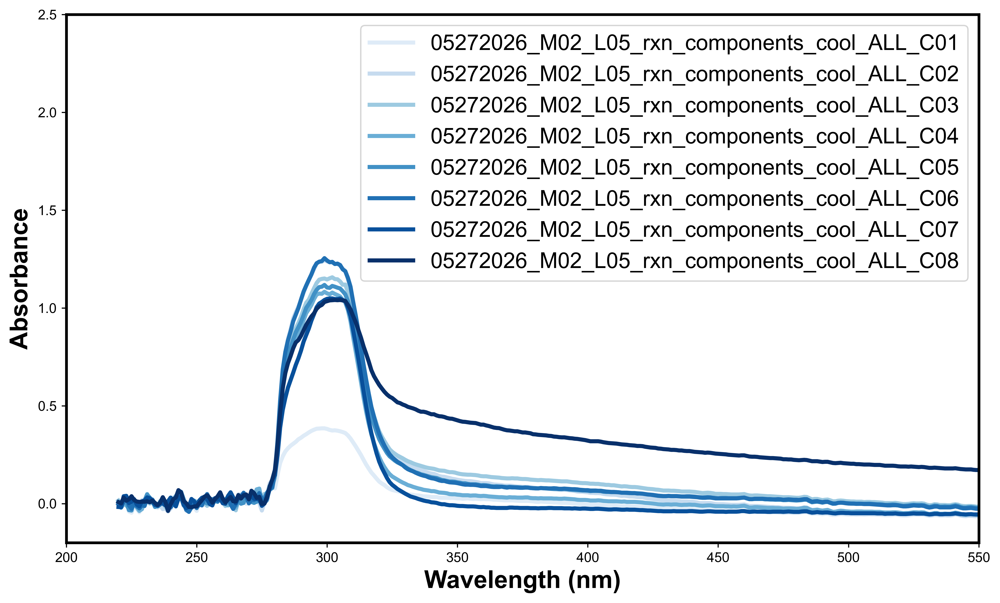

In [ ]:
# after cooling
# dtbbpyNiBr2 + silane

example= ["05272026_M02_L05_rxn_components_cool_ALL_C01",
          "05272026_M02_L05_rxn_components_cool_ALL_C02",
          "05272026_M02_L05_rxn_components_cool_ALL_C03",
          "05272026_M02_L05_rxn_components_cool_ALL_C04",
          "05272026_M02_L05_rxn_components_cool_ALL_C05",
          "05272026_M02_L05_rxn_components_cool_ALL_C06",
          "05272026_M02_L05_rxn_components_cool_ALL_C07",
          "05272026_M02_L05_rxn_components_cool_ALL_C08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/2752924131.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


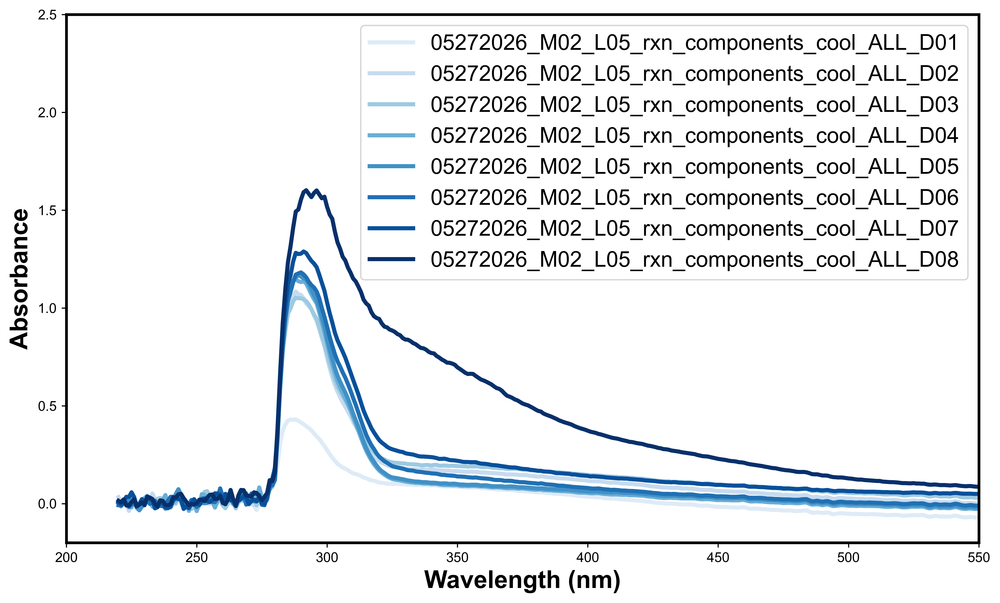

In [ ]:
# after cooling
# dtbbpyNiBr2 + base + silane

example= ["05272026_M02_L05_rxn_components_cool_ALL_D01",
          "05272026_M02_L05_rxn_components_cool_ALL_D02",
          "05272026_M02_L05_rxn_components_cool_ALL_D03",
          "05272026_M02_L05_rxn_components_cool_ALL_D04",
          "05272026_M02_L05_rxn_components_cool_ALL_D05",
          "05272026_M02_L05_rxn_components_cool_ALL_D06",
          "05272026_M02_L05_rxn_components_cool_ALL_D07",
          "05272026_M02_L05_rxn_components_cool_ALL_D08",
          ]

plot_h5_blue_scheme_time_course(input_h5, example)

In [6]:
def plot_excel_time_course(excel_file_paths, target_spectra=None, output_file_path=None, title=None, color_scheme="blue"):
    """
    Plots absorbance spectra from one or more Excel files, searching all sheets in each file.
    Spectra are plotted in the order specified by target_spectra.

    Parameters:
        excel_file_paths (str or list of str): Path(s) to Excel file(s) (.xlsx).
        target_spectra (str or list of str, optional): Column header names to plot.
            If None, plots all spectra columns found across all files and sheets.
        output_file_path (str, optional): If given, saves the plot to this folder; otherwise displays it.
        title (str, optional): Title for the plot.
        color_scheme (str): Either "blue" for the Blues colormap or "colorblind" for seaborn's colorblind palette.

    Returns:
        None
    """
    try:
        # Normalize inputs to lists
        if isinstance(excel_file_paths, str):
            excel_file_paths = [excel_file_paths]
        if isinstance(target_spectra, str):
            target_spectra = [target_spectra]

        # Pre-load all sheets from all files once
        all_sheets = []  # list of (file_path, sheet_name, df)
        for file_path in excel_file_paths:
            try:
                sheet_names = pd.ExcelFile(file_path).sheet_names
            except Exception as e:
                print(f"Warning: could not open '{file_path}': {e}")
                continue
            for sheet_name in sheet_names:
                try:
                    df = pd.read_excel(file_path, sheet_name=sheet_name, index_col=0)
                    all_sheets.append((file_path, sheet_name, df))
                except Exception as e:
                    print(f"Warning: could not parse sheet '{sheet_name}' in '{file_path}': {e}")

        if not all_sheets:
            print("No sheets could be loaded from the provided files.")
            return

        collected = []
        found_spectra = set()

        if target_spectra:
            # Outer loop over target_spectra preserves the user-specified plot order
            for col_name in target_spectra:
                for file_path, sheet_name, df in all_sheets:
                    if col_name not in df.columns:
                        continue
                    try:
                        wavelengths = df.index.to_numpy(dtype=float)
                        absorbances = df[col_name].to_numpy(dtype=float)
                    except Exception as e:
                        print(f"Warning: could not convert '{col_name}' in sheet '{sheet_name}': {e}")
                        continue
                    collected.append((wavelengths, absorbances, col_name))
                    found_spectra.add(col_name)
                    break  # Stop after first match to avoid duplicates across sheets

            missing = [s for s in target_spectra if s not in found_spectra]
            if missing:
                print(f"Warning: these spectra were not found in any file or sheet and will be skipped: {missing}")

        else:
            # No target specified — collect everything in file/sheet order
            for file_path, sheet_name, df in all_sheets:
                for col_name in df.columns:
                    try:
                        wavelengths = df.index.to_numpy(dtype=float)
                        absorbances = df[col_name].to_numpy(dtype=float)
                    except Exception as e:
                        print(f"Warning: could not convert '{col_name}' in sheet '{sheet_name}': {e}")
                        continue
                    collected.append((wavelengths, absorbances, col_name))

        if not collected:
            print("No datasets matched the specified criteria.")
            return

        # Build color list
        num_colors = len(collected)
        if color_scheme == "blue":
            cmap = get_cmap("Blues")
            colors = [cmap(0.3 + 0.7 * i / max(num_colors - 1, 1)) for i in range(num_colors)]
        elif color_scheme == "colorblind":
            colors = sns.color_palette("colorblind", num_colors)
        else:
            raise ValueError(f"Invalid color_scheme '{color_scheme}'. Choose 'blue' or 'colorblind'.")

        # Plot
        plt.figure(figsize=(12, 7), dpi=600)
        for idx, (wavelengths, absorbances, label) in enumerate(collected):
            plt.plot(wavelengths, absorbances, linewidth=3.0, label=label, color=colors[idx])

        plt.title(title, fontsize=24)
        plt.xlabel("Wavelength (nm)", fontsize=18)
        plt.ylabel("Absorbance", fontsize=18)
        plt.legend(fontsize=16)
        plt.grid(False)
        plt.xlim(220, 550)
        plt.ylim(-0.6, 3)

        if output_file_path:
            os.makedirs(output_file_path, exist_ok=True)
            output_file = os.path.join(output_file_path, f"overlaid_spectra_{color_scheme}.svg")
            plt.savefig(output_file, bbox_inches='tight')
            print(f"Plot saved: {output_file}")
        else:
            plt.show()
        plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")

In [ ]:
input_excel = ["UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/RawData_Rxn_Componenets_Shimadzu.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/RawData_Ni(dtbbpy)Br2_rxn_componenets.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/RawData_Ni_OA_adduct.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/NicomplexesintolandDMF.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/RawData_addBr and dinitro ligand.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/Raw Data - add Br 1to1 with Ni and sonicatred prestir-complex.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/RawData_rxncomponernt_controls.xlsx",
               "UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/ni complexes uv-vis.xlsx"]


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


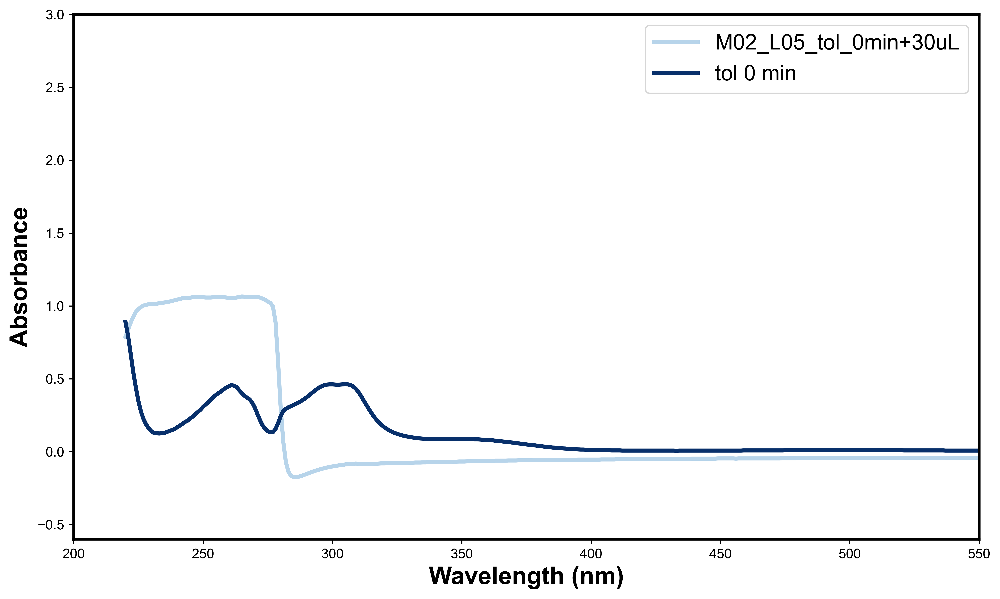

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


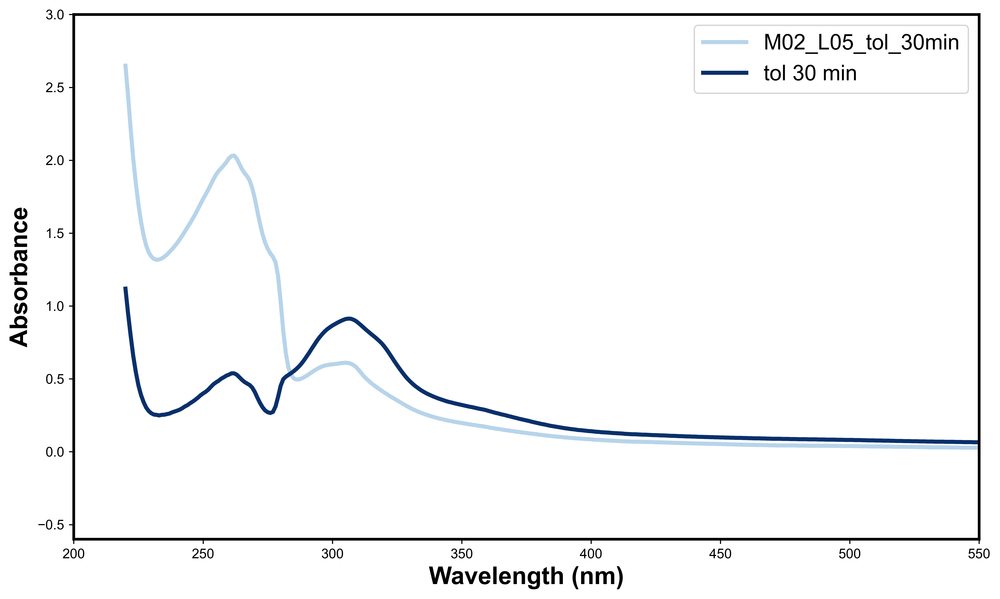

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


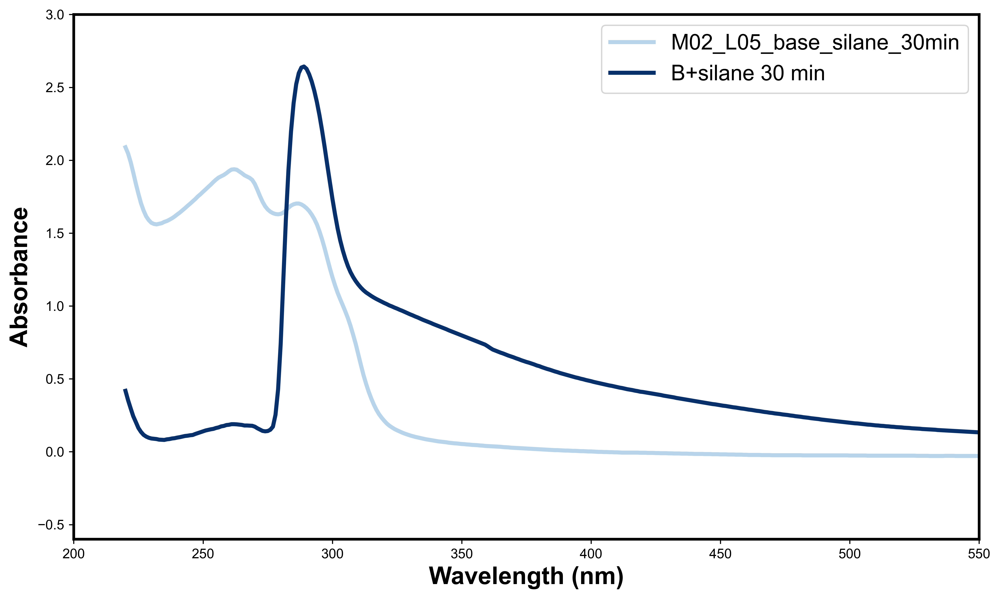

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


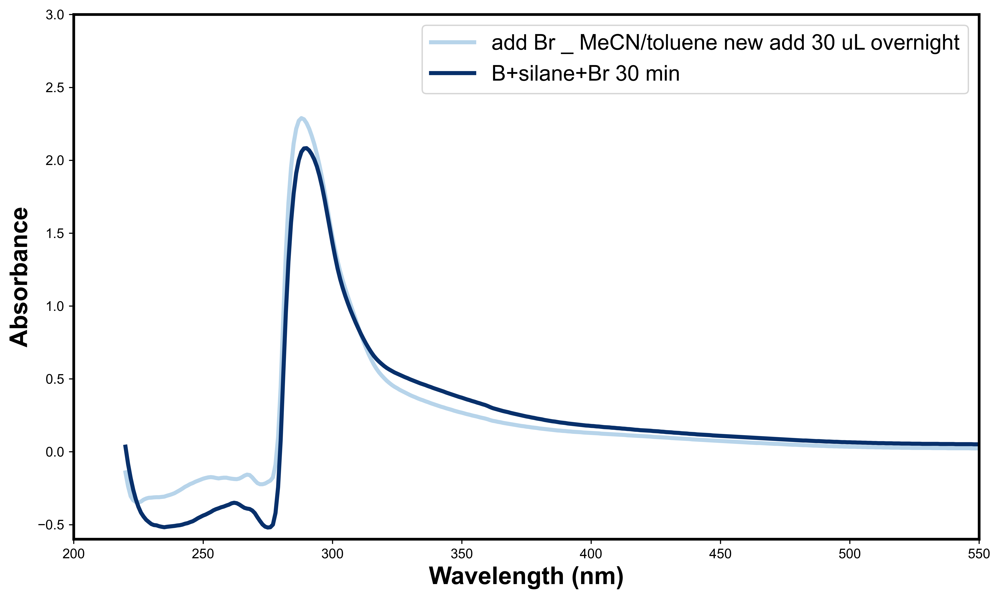

In [ ]:

zero_min = ["M02_L05_tol_0min+30uL",
           "tol 0 min"]

thirty_min = ["M02_L05_tol_30min",
           "tol 30 min"]

thirty_min_base_silane = ["M02_L05_base_silane_30min",
           "B+silane 30 min"]

thirty_min_base_silane_br = ["add Br _ MeCN/toluene new add 30 uL overnight",
           "B+silane+Br 30 min"]


plot_excel_time_course(input_excel, zero_min, color_scheme="blue")
plot_excel_time_course(input_excel, thirty_min, color_scheme="blue")
plot_excel_time_course(input_excel, thirty_min_base_silane, color_scheme="blue")
plot_excel_time_course(input_excel, thirty_min_base_silane_br, color_scheme="blue")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_4504/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


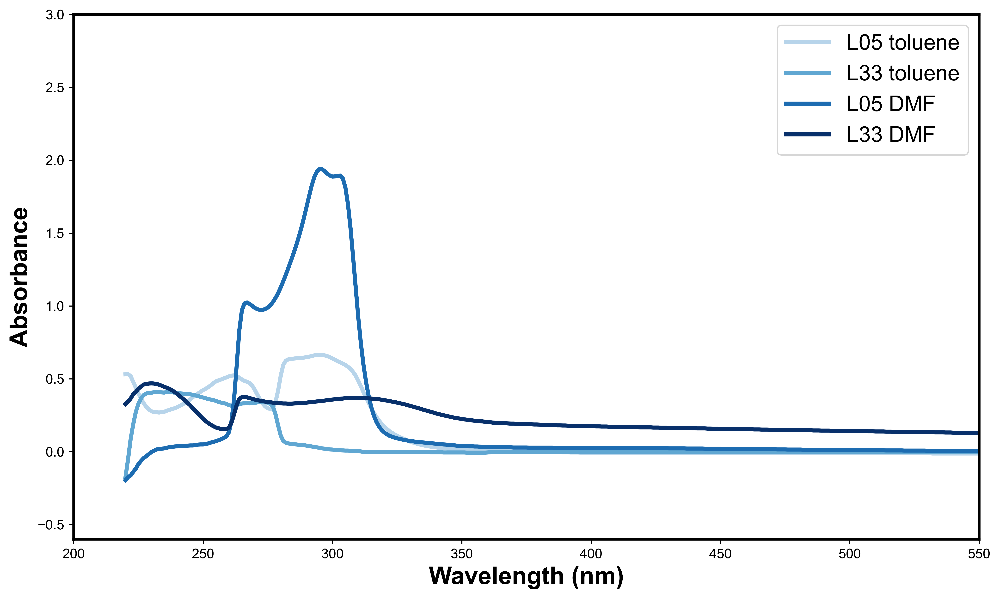

In [ ]:
OA_complex = ["L05 toluene","L33 toluene",
            "L05 DMF","L33 DMF",
            ]

plot_excel_time_course(input_excel, OA_complex, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_17825/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


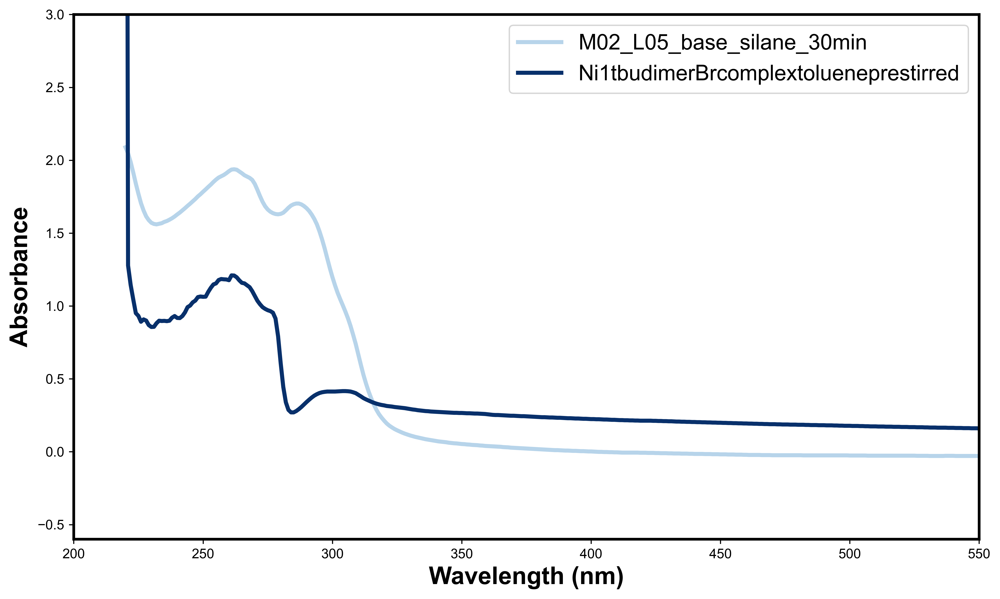

In [ ]:
dimer = ["Ni1tbudimerBrcomplextolueneprestirred",
         "M02_L05_base_silane_30min"]

plot_excel_time_course(input_excel, dimer, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_17825/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


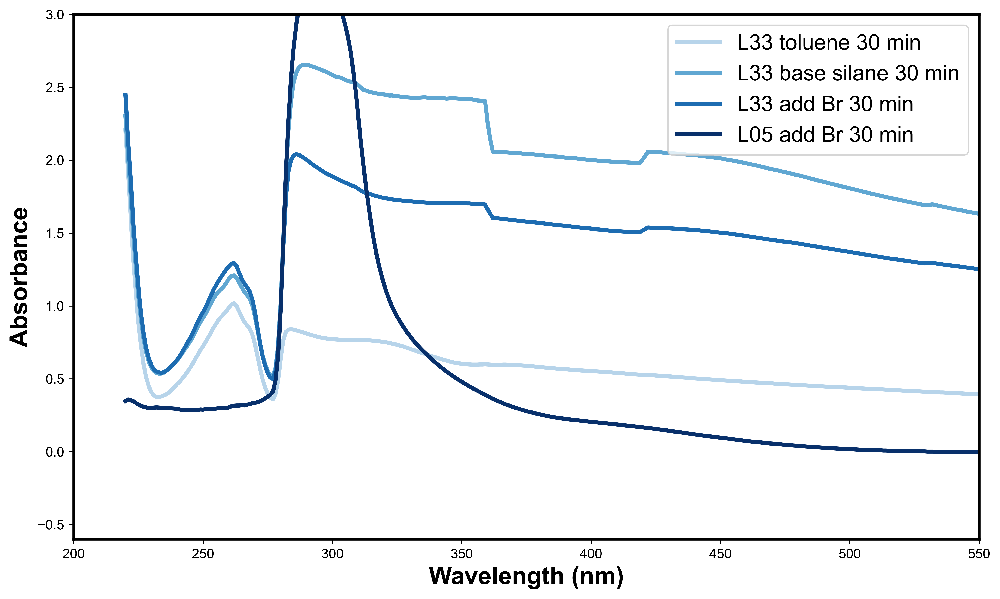

In [ ]:
OA_time_course = ["L33 toluene 30 min","L33 base silane 30 min",
            "L33 add Br 30 min","L05 add Br 30 min",
            ]

plot_excel_time_course(input_excel, OA_time_course, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_17825/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


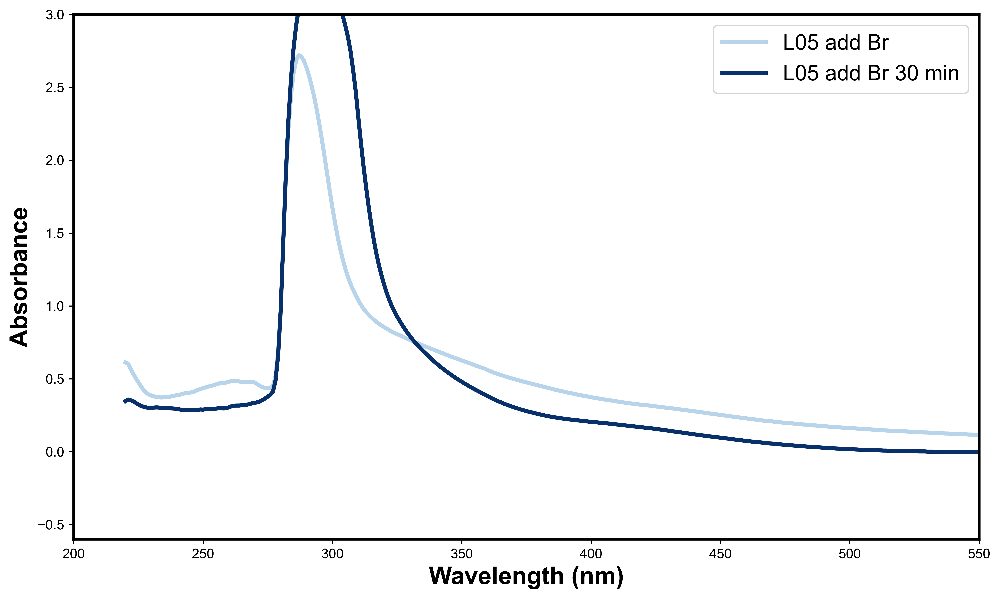

In [ ]:
example = ["L05 add Br","L05 add Br 30 min",
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/1825856951.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


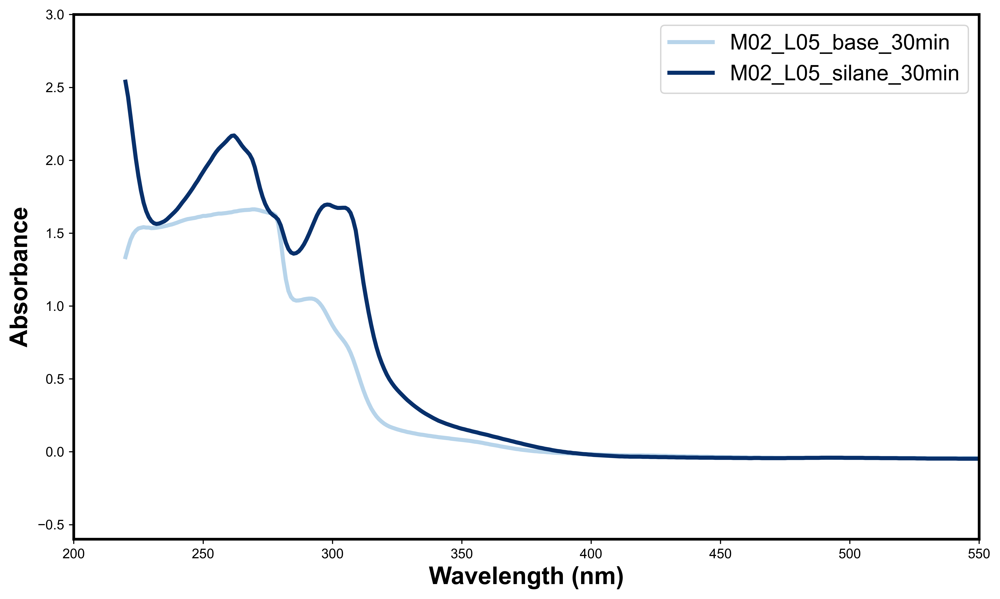

In [ ]:
example = ["M02_L05_base_30min","M02_L05_silane_30min"
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/2751045110.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


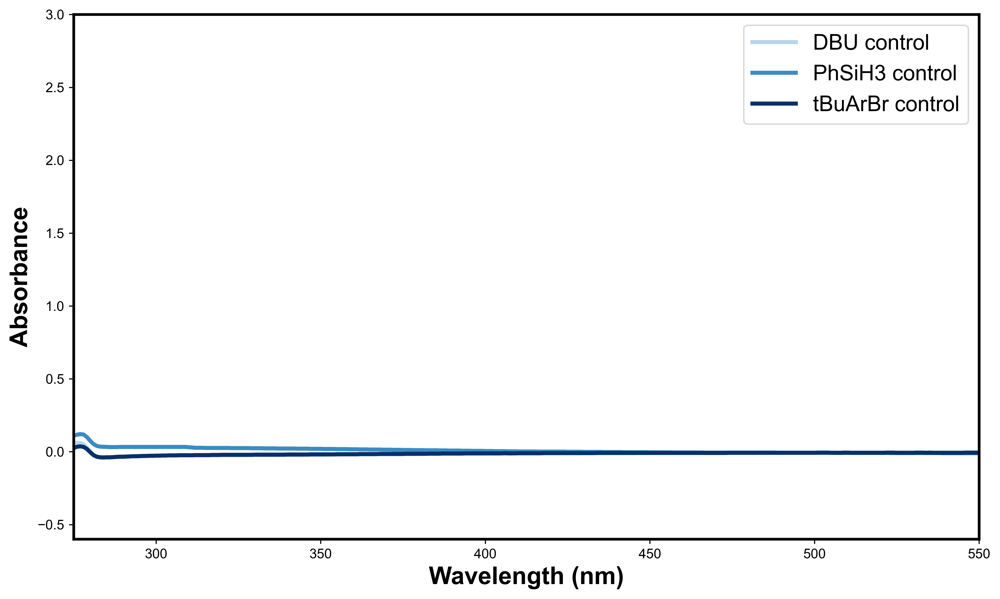

In [63]:
reaction_controls = ["DBU control", "PhSiH3 control", "tBuArBr control"]
plot_excel_time_course(input_excel, reaction_controls, color_scheme="blue")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/2751045110.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


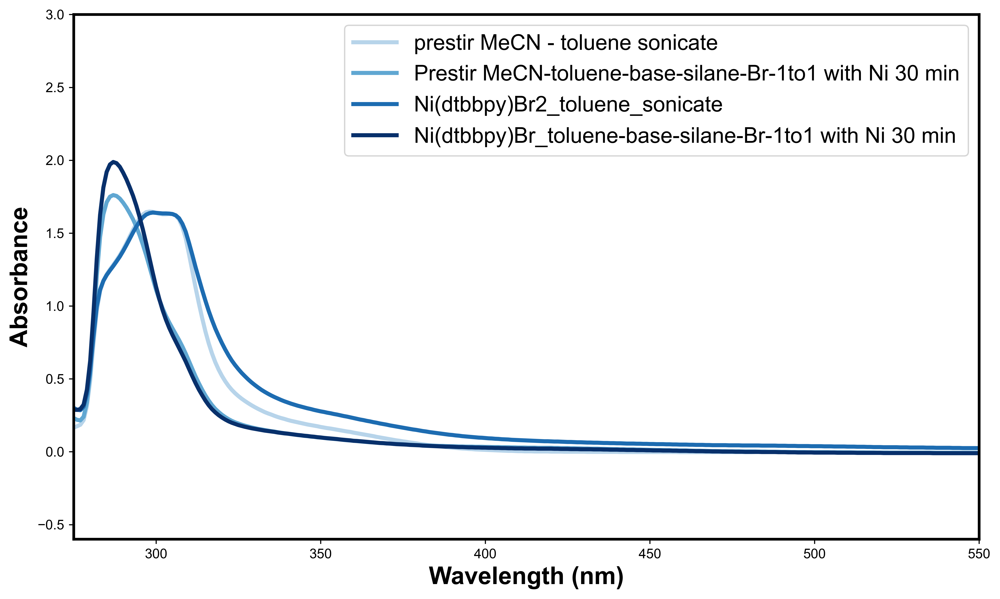

In [ ]:
OA_1_1 = ["prestir MeCN - toluene sonicate",
          "Prestir MeCN-toluene-base-silane-Br-1to1 with Ni 30 min",
          "Ni(dtbbpy)Br2_toluene_sonicate",
          "Ni(dtbbpy)Br_toluene-base-silane-Br-1to1 with Ni 30 min"
            ]

plot_excel_time_course(input_excel, OA_1_1, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/689248279.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


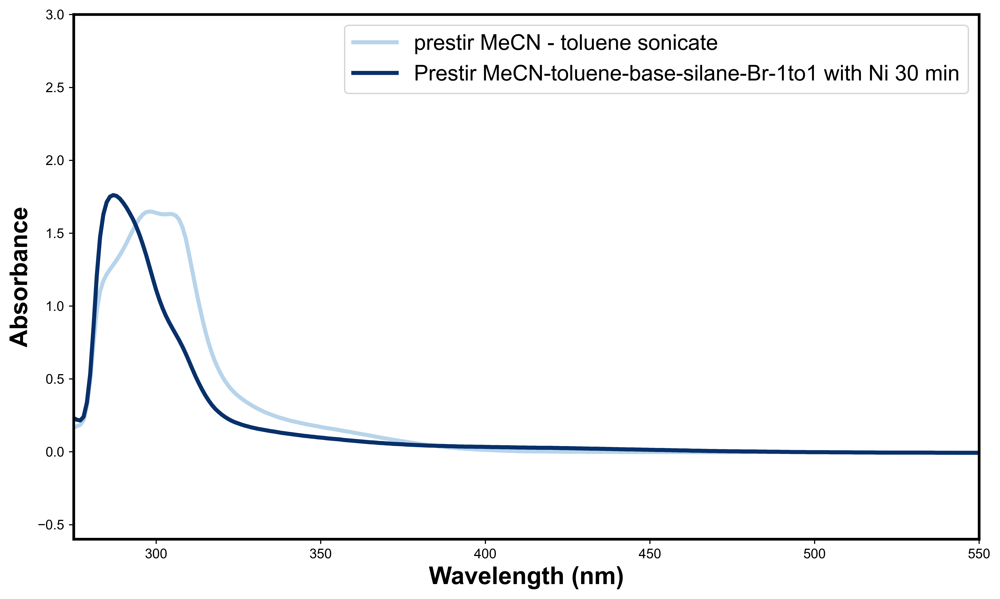

In [ ]:
OA_1_1 = ["prestir MeCN - toluene sonicate",
          "Prestir MeCN-toluene-base-silane-Br-1to1 with Ni 30 min",
          #"Ni(dtbbpy)Br2_toluene_sonicate",
          #"Ni(dtbbpy)Br_toluene-base-silane-Br-1to1 with Ni 30 min"
            ]

plot_excel_time_course(input_excel, OA_1_1, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/2751045110.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


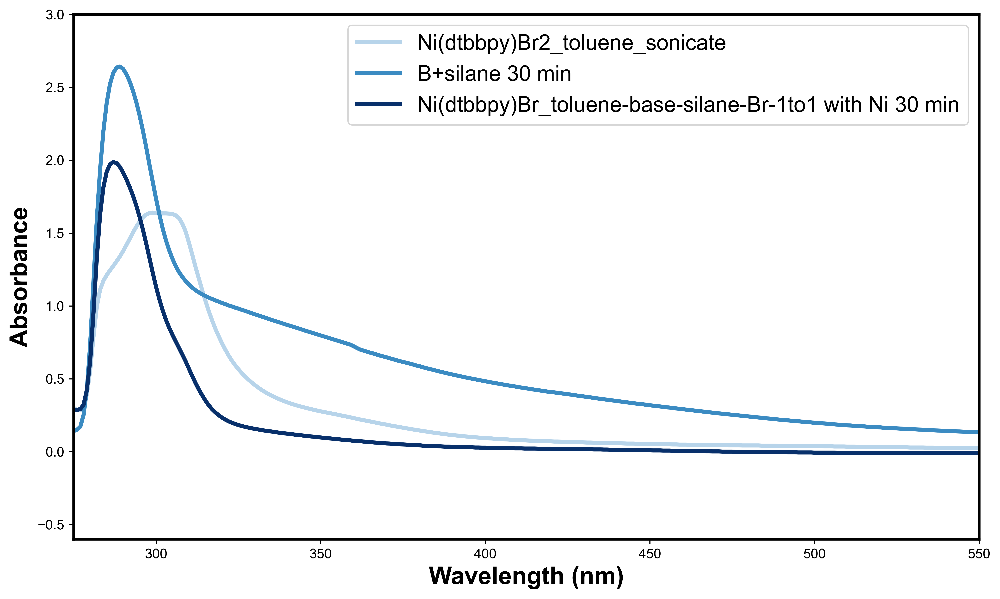

In [58]:
example = [           
    "Ni(dtbbpy)Br2_toluene_sonicate",
    "B+silane 30 min",
           "Ni(dtbbpy)Br_toluene-base-silane-Br-1to1 with Ni 30 min"
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/2751045110.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


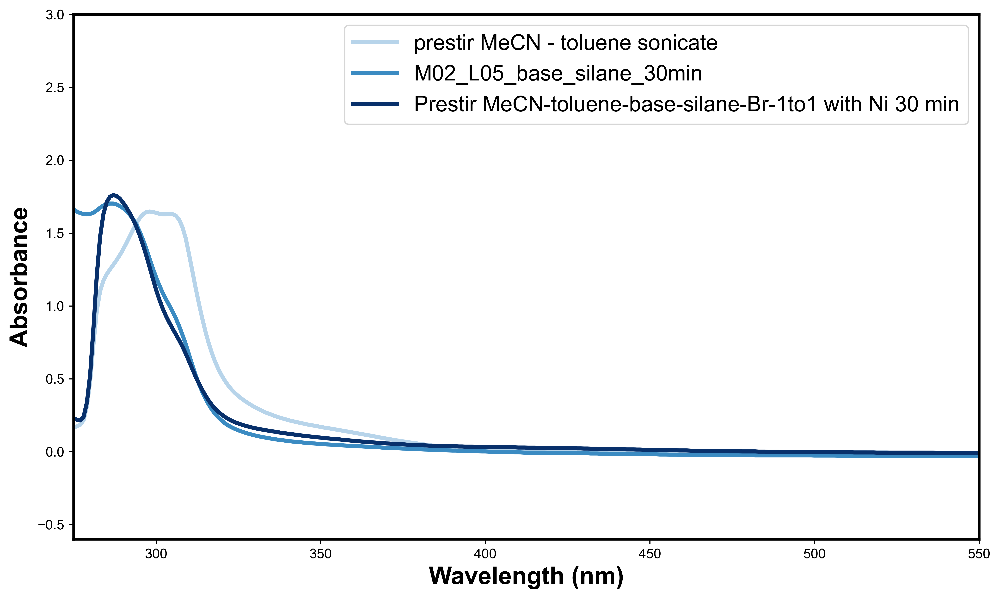

In [ ]:
example = ["prestir MeCN - toluene sonicate",
           "M02_L05_base_silane_30min",
           "Prestir MeCN-toluene-base-silane-Br-1to1 with Ni 30 min",
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_23816/689248279.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


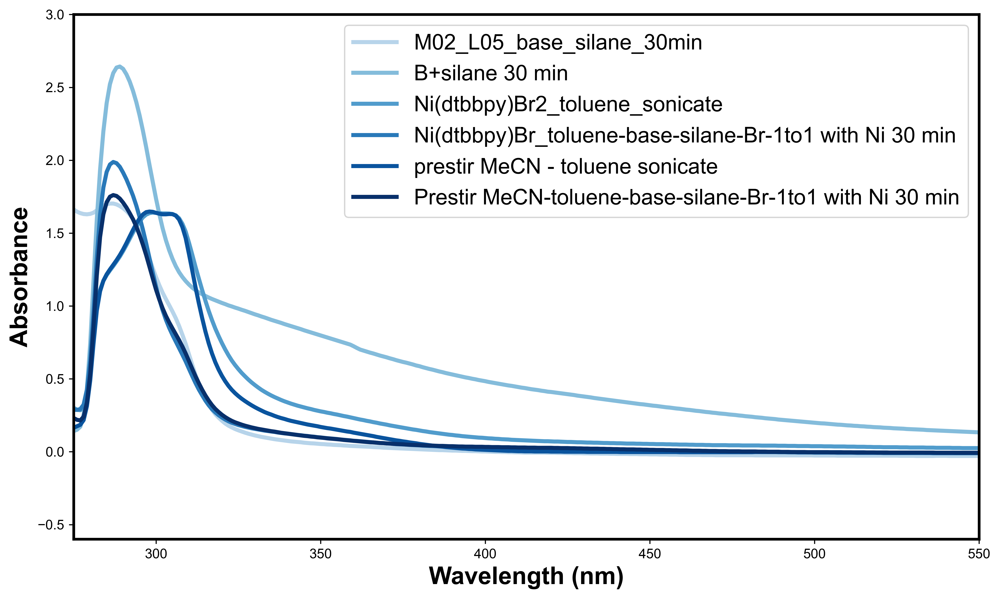

In [ ]:
example = ["Ni(dtbbpy)Br2_toluene_sonicate",
           "B+silane 30 min",
           "Ni(dtbbpy)Br_toluene-base-silane-Br-1to1 with Ni 30 min",
            "M02_L05_base_silane_30min",
           "prestir MeCN - toluene sonicate",
           "Prestir MeCN-toluene-base-silane-Br-1to1 with Ni 30 min",
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_29829/1947005752.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


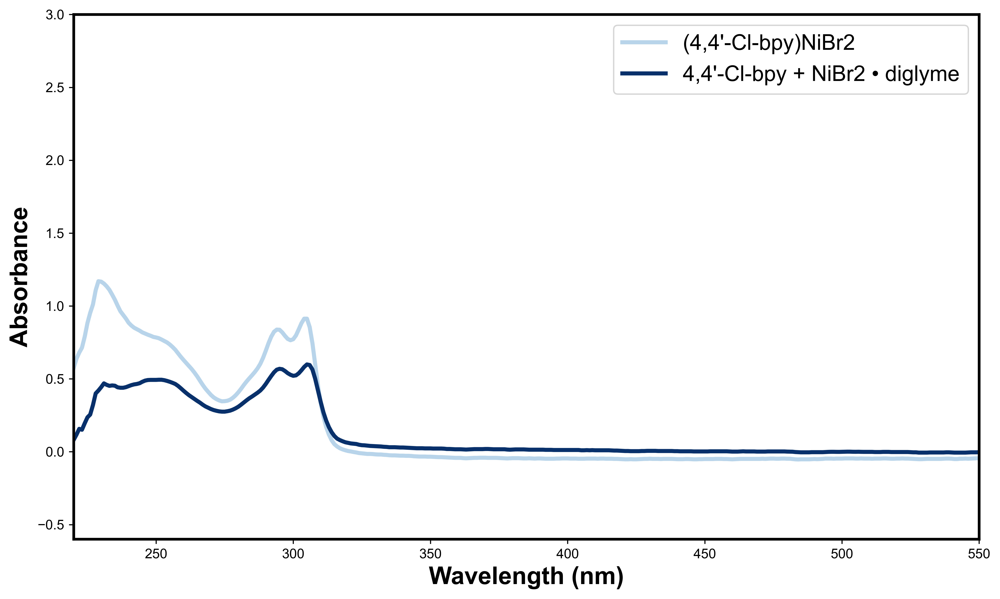

In [7]:
example = ["(4,4'-Cl-bpy)NiBr2",
        "4,4'-Cl-bpy + NiBr2 • diglyme"
            ]

plot_excel_time_course(input_excel, example, color_scheme="blue")


In [37]:
import re

def plot_mixed_time_course(
    file_paths,
    target_spectra_excel=None,
    target_spectra_h5=None,
    plot_order=None,
    output_file_path="SVG Exports",
    file_name=None,
    title=None,
    color_scheme="blue"
):
    """
    Plots absorbance spectra from a mix of Excel (.xlsx) and HDF5 (.h5) files.

    Parameters:
        file_paths (str or list of str): Path(s) to Excel and/or HDF5 files.
        target_spectra_excel (str or list of str, optional): Column names to plot from Excel files.
            Plotted in the order provided. If None, plots all columns found in Excel files.
        target_spectra_h5 (str or list of str, optional): Dataset keys to plot from HDF5 files.
            Plotted in the order provided. If None, plots all datasets found in HDF5 files.
        plot_order (list of str, optional): If provided, overrides the default ordering
            (Excel first, then HDF5) by specifying a combined sequence of dataset names
            drawn from both target_spectra_excel and target_spectra_h5. Names not in this
            list will not be plotted even if present in the target lists.
            Example: ["h5_key_1", "excel_col_A", "h5_key_2", "excel_col_B"]
        output_file_path (str, optional): Folder the SVG is saved to (created if missing).
            Defaults to "SVG Exports". Pass None to skip saving.
        file_name (str, optional): Name of the SVG file (".svg" added if missing). Defaults to the
            title, or the plotted spectrum names joined by "__" if no title is given.
        title (str, optional): Title for the plot.
        color_scheme (str): Either "blue" for the Blues colormap or "colorblind" for seaborn's colorblind palette.

    Returns:
        None
    """
    try:
        # Normalize inputs to lists
        if isinstance(file_paths, str):
            file_paths = [file_paths]
        if isinstance(target_spectra_excel, str):
            target_spectra_excel = [target_spectra_excel]
        if isinstance(target_spectra_h5, str):
            target_spectra_h5 = [target_spectra_h5]

        # ── Pre-load all Excel sheets ──────────────────────────────────────────
        all_sheets = []  # list of (file_path, sheet_name, df)
        for file_path in file_paths:
            ext = os.path.splitext(file_path)[-1].lower()
            if ext not in (".xlsx", ".xls"):
                continue
            try:
                sheet_names = pd.ExcelFile(file_path).sheet_names
            except Exception as e:
                print(f"Warning: could not open '{file_path}': {e}")
                continue
            for sheet_name in sheet_names:
                try:
                    df = pd.read_excel(file_path, sheet_name=sheet_name, index_col=0)
                    all_sheets.append((file_path, sheet_name, df))
                except Exception as e:
                    print(f"Warning: could not parse sheet '{sheet_name}' in '{file_path}': {e}")

        # ── Pre-load all HDF5 datasets ─────────────────────────────────────────
        all_h5 = {}  # key -> (wavelengths, absorbances)
        for file_path in file_paths:
            ext = os.path.splitext(file_path)[-1].lower()
            if ext not in (".h5", ".hdf5"):
                continue
            try:
                with h5py.File(file_path, 'r') as hdf:
                    for key in hdf.keys():
                        if key not in all_h5:  # first file wins on name collision
                            try:
                                data = hdf[key][:]
                                all_h5[key] = (data[:, 0], data[:, 1])
                            except Exception as e:
                                print(f"Warning: could not read dataset '{key}' in '{file_path}': {e}")
            except Exception as e:
                print(f"Warning: could not open '{file_path}': {e}")

        # ── Helper: look up one Excel column across all sheets ─────────────────
        def find_excel(col_name):
            for file_path, sheet_name, df in all_sheets:
                if col_name in df.columns:
                    try:
                        return df.index.to_numpy(dtype=float), df[col_name].to_numpy(dtype=float)
                    except Exception as e:
                        print(f"Warning: could not convert '{col_name}' in sheet '{sheet_name}': {e}")
            return None

        # ── Collect in the right order ─────────────────────────────────────────
        collected = []  # list of (wavelengths, absorbances, label)
        found_excel = set()
        found_h5 = set()

        excel_set = set(target_spectra_excel) if target_spectra_excel else set()
        h5_set = set(target_spectra_h5) if target_spectra_h5 else set()

        def append_excel(col_name):
            result = find_excel(col_name)
            if result:
                collected.append((*result, col_name))
                found_excel.add(col_name)
            else:
                print(f"Warning: Excel spectrum '{col_name}' not found in any file/sheet.")

        def append_h5(key):
            if key in all_h5:
                collected.append((*all_h5[key], key))
                found_h5.add(key)
            else:
                print(f"Warning: HDF5 dataset '{key}' not found in any file.")

        if plot_order:
            # Use plot_order as the single source of truth for sequence
            for name in plot_order:
                if name in excel_set:
                    append_excel(name)
                elif name in h5_set:
                    append_h5(name)
                else:
                    print(f"Warning: '{name}' in plot_order not found in either target list.")
        else:
            # Default: Excel in target_spectra_excel order, then HDF5 in target_spectra_h5 order
            if target_spectra_excel:
                for col_name in target_spectra_excel:
                    append_excel(col_name)
            else:
                for _, _, df in all_sheets:
                    for col_name in df.columns:
                        if col_name not in found_excel:
                            append_excel(col_name)

            if target_spectra_h5:
                for key in target_spectra_h5:
                    append_h5(key)
            else:
                for key in all_h5:
                    append_h5(key)

        # Warn about anything requested but never found
        if target_spectra_excel:
            missing = [s for s in target_spectra_excel if s not in found_excel]
            if missing:
                print(f"Warning: Excel spectra not found in any file/sheet: {missing}")
        if target_spectra_h5:
            missing = [s for s in target_spectra_h5 if s not in found_h5]
            if missing:
                print(f"Warning: HDF5 datasets not found in any file: {missing}")

        if not collected:
            print("No datasets matched the specified criteria.")
            return

        # ── Build colors ───────────────────────────────────────────────────────
        num_colors = len(collected)
        if color_scheme == "blue":
            cmap = get_cmap("Blues")
            colors = [cmap(0.3 + 0.7 * i / max(num_colors - 1, 1)) for i in range(num_colors)]
        elif color_scheme == "colorblind":
            colors = sns.color_palette("colorblind", num_colors)
        else:
            raise ValueError(f"Invalid color_scheme '{color_scheme}'. Choose 'blue' or 'colorblind'.")

        # ── Plot ───────────────────────────────────────────────────────────────
        # Keep SVG text as editable text (not paths) for Illustrator/Inkscape
        plt.rcParams['svg.fonttype'] = 'none'
        plt.figure(figsize=(12, 7), dpi=600)
        for idx, (wavelengths, absorbances, label) in enumerate(collected):
            plt.plot(wavelengths, absorbances, linewidth=3.0, label=label, color=colors[idx])

        plt.title(title, fontsize=24)
        plt.xlabel("Wavelength (nm)", fontsize=18)
        plt.ylabel("Absorbance", fontsize=18)
        plt.legend(fontsize=16)
        plt.grid(False)
        plt.xlim(250, 450)
        plt.ylim(-0.1, 2.0)

        if output_file_path:
            if not file_name:
                file_name = title if title else "__".join(label for _, _, label in collected)
            # Strip characters that are invalid in file names
            file_name = re.sub(r'[\\/:*?"<>|•]+', '_', file_name).strip()
            if not file_name.lower().endswith(".svg"):
                file_name += ".svg"
            os.makedirs(output_file_path, exist_ok=True)
            output_file = os.path.join(output_file_path, file_name)
            plt.savefig(output_file, format="svg", bbox_inches='tight')
            print(f"Plot saved: {output_file}")
        plt.show()
        plt.close()

    except Exception as e:
        print(f"An error occurred: {e}")

/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_16280/1943412590.py:159: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


Plot saved: SVG Exports/M02_L00_S03_B01_X__(4,4'-Cl-bpy)NiBr2__4,4'-Cl-bpy + NiBr2 _ diglyme.svg


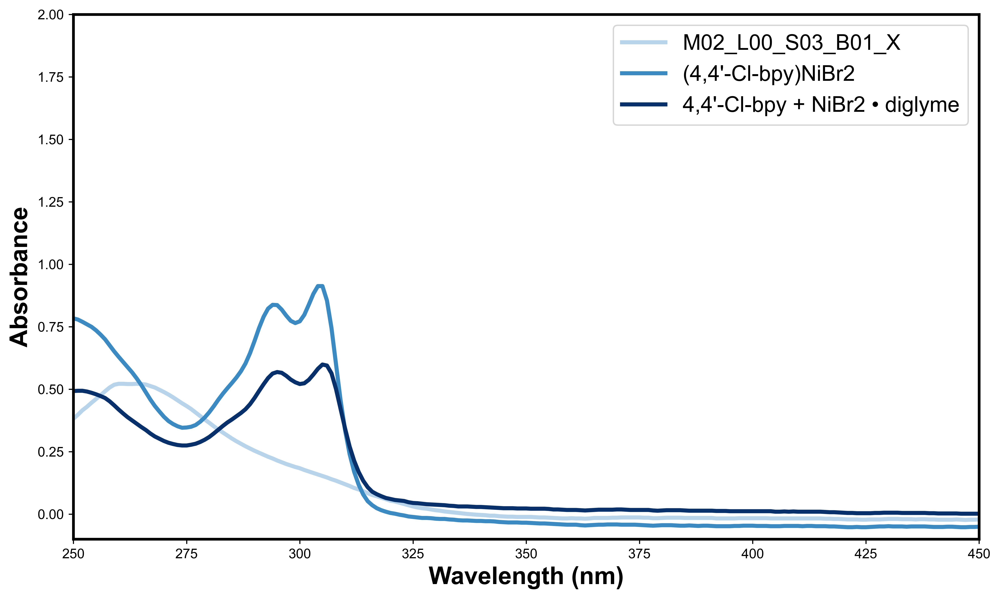

In [41]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library Controls.h5"
input_excel = ["UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/ni complexes uv-vis.xlsx"]
excel = ["(4,4'-Cl-bpy)NiBr2",
        "4,4'-Cl-bpy + NiBr2 • diglyme"
        ]

plot_mixed_time_course(
    file_paths=input_excel + [input_h5],
    target_spectra_excel=excel,
    target_spectra_h5=["M02_L00_S03_B01_X"],
    color_scheme="blue",
    plot_order=["M02_L00_S03_B01_X"] + excel
)


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_29829/4202655648.py:153: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


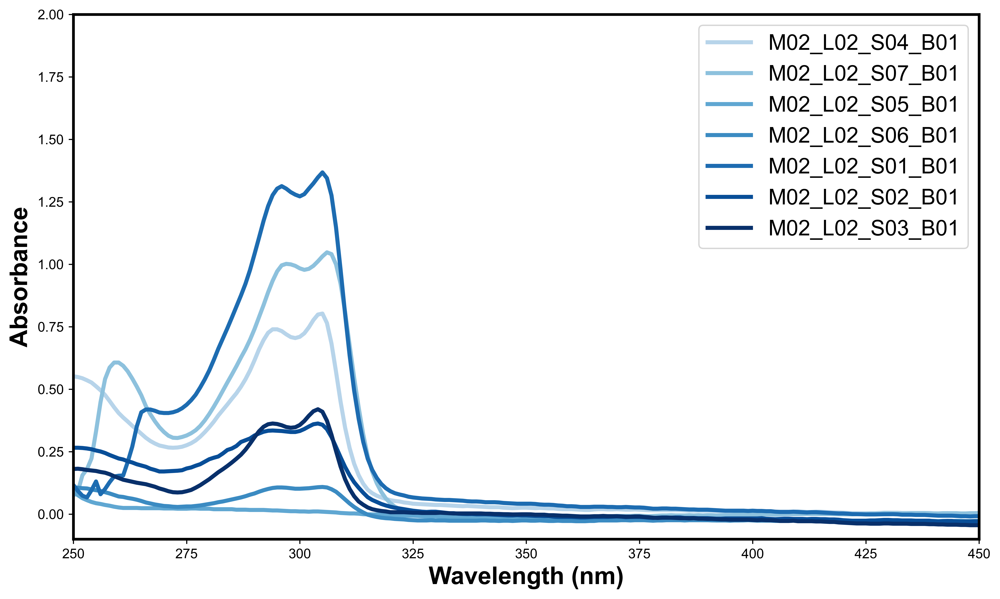

In [91]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
input_excel = ["UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/ni complexes uv-vis.xlsx"]
excel = ["(4,4'-Cl-bpy)NiBr2",
        "4,4'-Cl-bpy + NiBr2 • diglyme"
        ]
bmg = ["M02_L02_S04_B01",
       "M02_L02_S07_B01",
       "M02_L02_S05_B01",
       "M02_L02_S06_B01",
       "M02_L02_S01_B01",
       "M02_L02_S02_B01",
       "M02_L02_S03_B01",
       ]

plot_mixed_time_course(
    file_paths=input_excel + [input_h5],
    target_spectra_excel=excel,
    target_spectra_h5=bmg,
    color_scheme="blue",
    plot_order=bmg
)


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_29829/4202655648.py:153: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


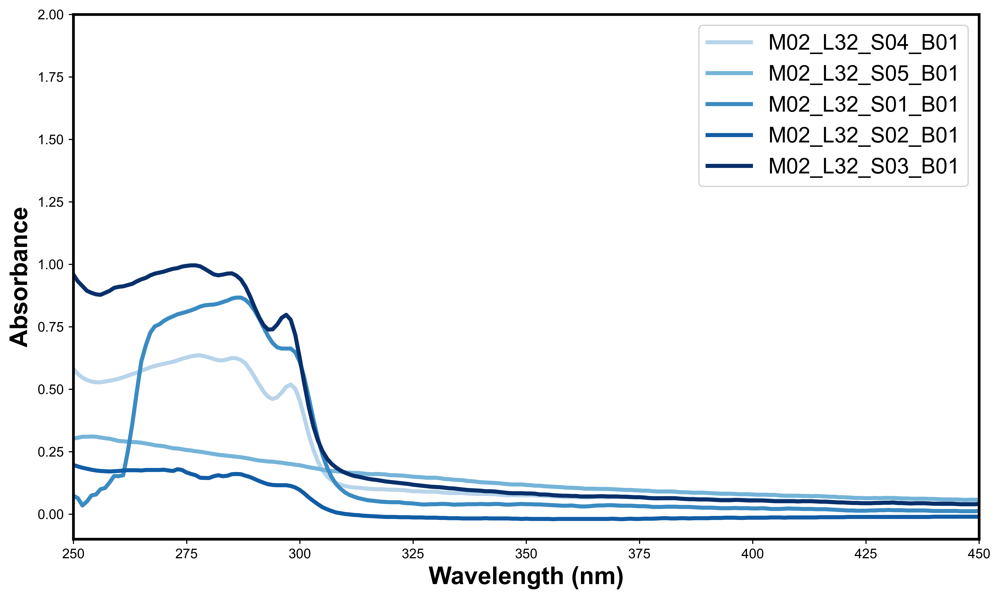

In [93]:
input_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
input_excel = ["UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/ni complexes uv-vis.xlsx"]
excel = ["(4,4'-Cl-bpy)NiBr2",
        "4,4'-Cl-bpy + NiBr2 • diglyme"
        ]
bmg = ["M02_L32_S04_B01",
       #"M02_L32_S07_B01",
       "M02_L32_S05_B01",
       #"M02_L32_S06_B01",
       "M02_L32_S01_B01",
       "M02_L32_S02_B01",
       "M02_L32_S03_B01",
       ]

plot_mixed_time_course(
    file_paths=input_excel + [input_h5],
    target_spectra_excel=excel,
    target_spectra_h5=bmg,
    color_scheme="blue",
    plot_order=bmg
)


/var/folders/c2/b3rpdcx52wj9_vyshmw7sjcm0000gn/T/ipykernel_29829/4202655648.py:153: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("Blues")


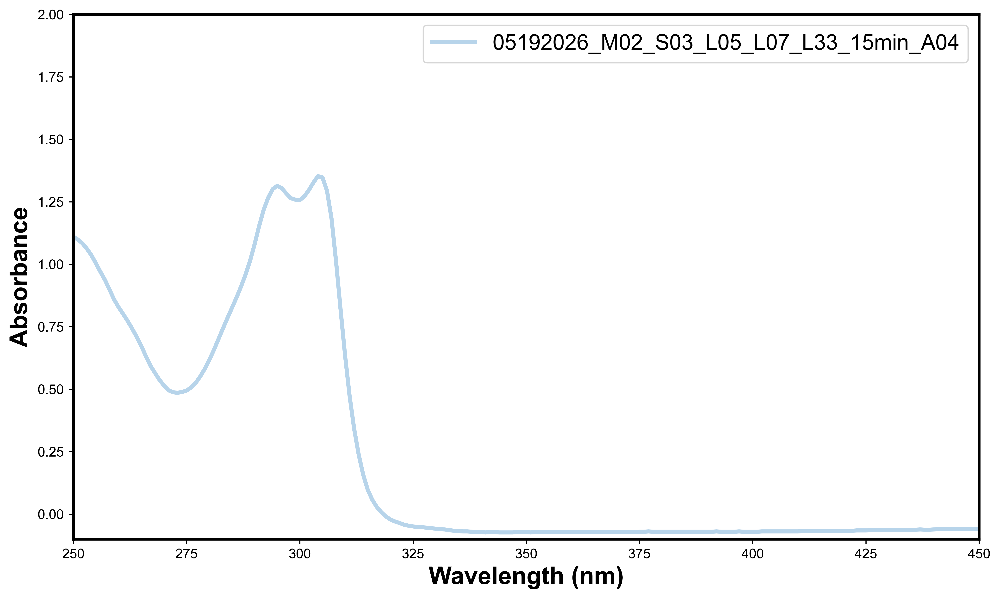

In [87]:

input_h5 = "UV-Vis Time Course/UV-Vis Time Course.h5"
input_excel = ["UV-Vis Time Course/05272026_rxn_components_TimeCourse_Shimadzu/Raw Data - add Br 1to1 with Ni and sonicatred prestir-complex.xlsx"]
   
excel = ["prestir MeCN - toluene sonicate"
           #"M02_L05_base_silane_30min",
           #"Prestir MeCN-toluene-base-silane-Br-1to1 with Ni 30 min",
           #"Ni(dtbbpy)Br_toluene-base-silane-Br-1to1 with Ni 30 min",
        ]

bmg = ["05192026_M02_S03_L05_L07_L33_15min_A04",
       "05192026_M02_S03_L05_L07_L33_15min_B04"
       "05192026_M02_S03_L05_L07_L33_15min_C04",
       "05192026_M02_S03_L05_L07_L33_15min_D04",]

plot_mixed_time_course(
    file_paths=input_excel + [input_h5],
    target_spectra_excel=excel,
    target_spectra_h5=bmg,
    color_scheme="blue",
    plot_order=bmg
)

